# C03c — Fifth-pass targeted X edits
Fresh kernel, Run All after C03. Canonical model: frozen full project-defined FZ186. No generation or retraining.

Three deterministic rules are evaluated separately and cumulatively: bracketed `[edit]` interface markers; recipe `>` separators verified from original line structure; sequential recipe step labels changed from `1.` to `Step 1:`. Numbers, ingredient quantities and instruction order are preserved. Recipe step candidates must be a complete increasing sequence starting at 1, have at least three members, and be tagged LS by the same spaCy model. A cross-reference check skips explicit step references. These constraints may leave candidates unchanged; skip reasons are logged.

Rules are applied without selecting edits by detector scores. Contribution changes are measured afterward. Original fixed54 stays untouched. Foreign expressions, URLs, meaningful brackets and ADD tokens await contextual rules. Review saved diffs before adopting these trial outputs. This is a discovery experiment, not a held-out confirmation.


In [14]:
from pathlib import Path
import json,hashlib,pickle,re,difflib
from collections import Counter
from functools import lru_cache
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy,textstat,sklearn
from IPython.display import display
ROOT=Path.cwd() if (Path.cwd()/'results').exists() else Path.cwd().parent
RUN_DIR=None
if RUN_DIR is None:
    runs=sorted(p.parent for p in (ROOT/'results/causal/C03_fz186_raid_fixed54').glob('*/summary.csv'))
    if len(runs)!=1:raise RuntimeError(f'Set RUN_DIR to one C03 run: {runs}')
    RUN_DIR=runs[0]
RUN_DIR=Path(RUN_DIR)
contract=json.loads((RUN_DIR/'contract.json').read_text());manifest=json.loads((RUN_DIR/'feature_manifest.json').read_text())
for rel,h in contract['inputs'].items():assert hashlib.sha256((ROOT/rel).read_bytes()).hexdigest()==h,f'Changed input: {rel}'
assert sklearn.__version__==contract['sklearn']
nlp=spacy.load('en_core_web_sm');assert nlp.meta==manifest['spacy']
BASE=ROOT/'results/causal/C02d2_fz118_ghostbuster_raid'
PRIOR=ROOT/'results/causal/C02e2_raid_feature_guided'
data=pd.read_csv(ROOT/'results/causal/C02w_adaptive_camouflage_v1/final_texts_54.csv',keep_default_na=False).sort_values('case_id').reset_index(drop=True)
assert len(data)==54 and data.case_id.is_unique and data.pipeline_status.eq('complete').all()
corpus=pd.read_parquet(BASE/'paired_corpus.parquet').set_index('source_id')
normalize=lambda t:str(t).replace('\n',' ').replace('\r',' ')
nb=ROOT/'experiments/C03c_targeted_X_edits.ipynb'
record=dict(parent=hashlib.sha256((RUN_DIR/'contract.json').read_bytes()).hexdigest(),code=hashlib.sha256(json.dumps([c['source'] for c in json.loads(nb.read_text())['cells'] if c['cell_type']=='code']).encode()).hexdigest(),policy='fixed rules; no score-based acceptance',bootstraps=2000)
run=hashlib.sha256(json.dumps(record,sort_keys=True).encode()).hexdigest()[:12]
OUT=ROOT/'results/causal/C03c_targeted_X_edits'/run;OUT.mkdir(parents=True,exist_ok=True)
FIG=ROOT/'figures';FIG.mkdir(exist_ok=True)
(OUT/'contract.json').write_text(json.dumps(record,indent=2))


236

In [15]:
import re, pickle
from collections import Counter
import textstat
PUNCTUATION = [('comma', ','), ('period', '.'), ('colon', ':'), ('semicolon', ';'),
    ('question', '?'), ('exclamation', '!'), ('hyphen', '-'), ('quote', '"'),
    ('lparen', '('), ('rparen', ')'), ('lbracket', '['), ('rbracket', ']'), ('newline', '\n')]
google_words=[w.strip().lower() for w in (BASE/'google-10000-english.txt').read_text().splitlines() if w.strip()]
GOOGLE_TOP={n:set(google_words[:n]) for n in [100,1000,10000]}

def safe_div(a, b):
    return float(a) / float(b) if b else 0.0


def clean_word_tokens(span):
    return [
        token.text.lower()
        for token in span
        if token.is_alpha
    ]


def clean_pos_tokens(span):
    return [
        token.pos_
        for token in span
        if token.is_alpha
    ]


def ngram_counter(sequence, n):
    if len(sequence) < n:
        return Counter()
    return Counter(
        tuple(sequence[i:i+n])
        for i in range(len(sequence) - n + 1)
    )


def multiset_overlap(left, right, n):
    a = ngram_counter(left, n)
    b = ngram_counter(right, n)
    denominator = min(sum(a.values()), sum(b.values()))
    if denominator == 0:
        return 0.0
    shared = sum((a & b).values())
    return float(shared / denominator)


def overlap_histogram(sentences, token_fn, n):
    if len(sentences) < 2:
        return np.zeros(10, dtype=np.float64)

    values = [
        multiset_overlap(token_fn(left), token_fn(right), n)
        for left, right in zip(sentences[:-1], sentences[1:])
    ]

    # Include 1.0 in the final bin.
    bins = np.minimum((np.asarray(values) * 10).astype(int), 9)
    counts = np.bincount(bins, minlength=10).astype(np.float64)
    return counts / max(1, len(values))


def conjunction_overlap(sentences, n):
    values = []
    for sentence in sentences:
        words = clean_word_tokens(sentence)
        for i, word in enumerate(words):
            if word == "and":
                values.append(
                    multiset_overlap(words[:i], words[i+1:], n)
                )
    return float(np.mean(values)) if values else 0.0


def punctuation_count(text, symbol_name, symbol):
    if symbol_name == "quote":
        return text.count('"') + text.count("“") + text.count("”")
    return text.count(symbol)


def finite_readability(fn, text):
    try:
        value = float(fn(text))
        return value if np.isfinite(value) else 0.0
    except Exception:
        return 0.0


def extract_fz118(text):
    text = str(text)
    doc = nlp(text)
    sentences = [sent for sent in doc.sents if clean_word_tokens(sent)]
    words = [token.text.lower() for token in doc if token.is_alpha]

    n_characters = len(text)
    n_words = len(words)
    n_sentences = len(sentences)
    n_syllables = int(textstat.syllable_count(text))
    n_difficult = int(textstat.difficult_words(text))
    n_short = sum(len(word) <= 3 for word in words)
    n_long = sum(len(word) >= 7 for word in words)

    values = [
        n_characters,
        n_syllables,
        n_words,
        n_sentences,
        n_difficult,
        n_short,
        n_long,
        safe_div(n_characters, n_words),
        safe_div(n_syllables, n_words),
        safe_div(n_words, n_sentences),
        safe_div(n_difficult, n_words),
        safe_div(n_short, n_words),
        safe_div(n_long, n_words),
        finite_readability(textstat.automated_readability_index, text),
        finite_readability(textstat.coleman_liau_index, text),
        finite_readability(textstat.flesch_kincaid_grade, text),
        finite_readability(textstat.flesch_reading_ease, text),
        finite_readability(textstat.gunning_fog, text),
        finite_readability(textstat.lix, text),
        finite_readability(textstat.mcalpine_eflaw, text),
        finite_readability(textstat.rix, text),
        finite_readability(textstat.smog_index, text),
        safe_div(sum(token.is_stop for token in doc if token.is_alpha), n_words),
        safe_div(len(set(words)), n_words),
        safe_div(sum(word in GOOGLE_TOP[100] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[1000] for word in words), n_words),
        safe_div(sum(word in GOOGLE_TOP[10000] for word in words), n_words),
    ]

    punct_counts = [
        punctuation_count(text, name, symbol)
        for name, symbol in PUNCTUATION
    ]
    values += [safe_div(count, n_characters) for count in punct_counts]
    values += [safe_div(count, n_sentences) for count in punct_counts]

    paragraphs = [p.strip() for p in re.split(r"\n\s*\n", text) if p.strip()]
    paragraph_word_counts = [
        sum(token.is_alpha for token in nlp.make_doc(paragraph))
        for paragraph in paragraphs
    ]
    values += [
        len(paragraphs),
        float(np.mean(paragraph_word_counts)) if paragraph_word_counts else 0.0,
    ]

    for token_fn in [clean_word_tokens, clean_pos_tokens]:
        for n in [1, 2, 3]:
            values += overlap_histogram(sentences, token_fn, n).tolist()

    values += [conjunction_overlap(sentences, n) for n in [1, 2, 3]]

    vector = np.asarray(values, dtype=np.float64)
    assert vector.shape == (118,)
    assert np.isfinite(vector).all()
    return vector
# Exact tree-path contributions, summed across the frozen forest.
FEATURE_NAMES=json.loads((BASE/'fz118_feature_contract.json').read_text())['feature_names']
model_features=json.loads((PRIOR/'fz118_raid_model_features.json').read_text())
with (PRIOR/'fz118_raid_no_parentheses_detector.pkl').open('rb') as f:detector=pickle.load(f)
assert list(detector.classes_)==[0,1]
def contributions(X):
    a=np.asarray(X,dtype=np.float32); output=np.zeros_like(a,dtype=float);bias=0.
    for estimator in detector.estimators_:
        tree=estimator.tree_; value=tree.value[:,0,:].astype(float)
        prob=value[:,1]/value.sum(axis=1);bias+=prob[0]/len(detector.estimators_)
        for i,row in enumerate(a):
            node=0
            while tree.children_left[node]!=tree.children_right[node]:
                feature=tree.feature[node]
                child=tree.children_left[node] if row[feature]<=tree.threshold[node] else tree.children_right[node]
                output[i,feature]+=(prob[child]-prob[node])/len(detector.estimators_)
                node=child
    assert np.allclose(bias+output.sum(axis=1),detector.predict_proba(X)[:,1],atol=1e-8)
    return output


@lru_cache(maxsize=8192)
def vector_for(text): return extract_fz118(normalize(text))
def frame_for(texts):
    return pd.DataFrame([vector_for(t) for t in texts],columns=FEATURE_NAMES)


In [16]:
with (RUN_DIR/'FZ186.pkl').open('rb') as f:detector=pickle.load(f)
COLS=manifest['feature_names'];assert list(detector.feature_names_in_)==COLS
XCOLS=[f'pos_X_{s}' for s in manifest['pos_statistics']]
def full_frame(texts):
    out=[]
    for text in texts:
        text=normalize(text);doc=nlp(text);ts=[t for t in doc if not t.is_space]
        counts=Counter(t.pos_ for t in ts)
        sentences=[Counter(t.pos_ for t in s if not t.is_space) for s in doc.sents if any(not t.is_space for t in s)]
        values=extract_fz118(text).tolist()
        for tag in manifest['pos_tags']:
            a=np.array([s[tag] for s in sentences],float)
            values.extend([counts[tag]/max(1,len(ts)),a.mean() if len(a) else 0,a.std() if len(a) else 0,a.max() if len(a) else 0])
        out.append(values)
    return pd.DataFrame(out,columns=COLS)
BASE_X=full_frame(data.text)
stored=pd.read_csv(RUN_DIR/'fixed54_features.csv').set_index('case_id').loc[data.case_id,COLS]
np.testing.assert_allclose(BASE_X,stored,atol=1e-9,rtol=0)
BASE_C=contributions(BASE_X)
stored_c=pd.read_csv(RUN_DIR/'FZ186_case_contributions.csv').set_index('case_id').loc[data.case_id,COLS]
np.testing.assert_allclose(BASE_C,stored_c,atol=1e-9)
BASE_G=pd.read_csv(RUN_DIR/'FZ186_case_contribution_gaps.csv').set_index('case_id').loc[data.case_id,COLS].to_numpy()
# Fixed per-case same-genre references from C03, never recomputed after edits.
REF=BASE_C-BASE_G


In [17]:
def apply_spans(text,spans):
    for start,end,replacement in sorted(spans,reverse=True):text=text[:start]+replacement+text[end:]
    return text

def edit_rule(text,genre,source):
    spans=[(m.start(),m.end(),'') for m in re.finditer(r'\[\s*edit\s*\]',text,re.I)]
    return apply_spans(text,spans),spans,'bracketed interface label' if spans else 'no bracketed edit marker'

def angle_rule(text,genre,source):
    if genre!='recipes':return text,[],'not recipe'
    raw=list(re.finditer(r'>',source))
    starts=list(re.finditer(r'(?m)^\s*>\s+\S',source))
    current=list(re.finditer('>',text))
    if len(raw)<3 or len(starts)!=len(raw) or len(current)!=len(raw):return text,[],'source does not verify repeated line prefixes or count changed'
    spans=[(m.start(),m.end(),'-') for m in current]
    return apply_spans(text,spans),spans,'source-verified recipe prefixes'

def list_rule(text, genre, source):
    from difflib import SequenceMatcher

    if genre != "recipes":
        return text, [], "not recipe"

    # Original layout supplies evidence that these are instruction labels.
    labels = list(re.finditer(
        r"(?m)^[ \t]*(\d{1,2})[.)][ \t]+(?=[A-Za-z])",
        source,
    ))

    # Accept consecutive runs, including excerpts starting after step 1.
    runs = []
    for m in labels:
        if runs and int(m.group(1)) == int(runs[-1][-1].group(1)) + 1:
            runs[-1].append(m)
        else:
            runs.append([m])
    labels = [m for run in runs if len(run) >= 3 for m in run]
    if not labels:
        return text, [], "no original consecutive instruction sequence"

    # Preserve offsets while aligning words, numbers, and punctuation.
    pattern = r"\d+(?:\.\d+)?|[^\W\d_]+(?:['’-][^\W\d_]+)*|[^\w\s]"
    src = list(re.finditer(pattern, source))
    cur = list(re.finditer(pattern, text))
    svals = [m.group().lower() for m in src]
    cvals = [m.group().lower() for m in cur]

    matcher = SequenceMatcher(None, svals, cvals, autojunk=False)
    mapping = {}
    for block in matcher.get_matching_blocks():
        mapping.update(
            (block.a + k, block.b + k) for k in range(block.size)
        )

    source_offsets = {m.start(): i for i, m in enumerate(src)}
    spans, skipped = [], []

    for label in labels:
        number = label.group(1)
        si = source_offsets.get(label.start(1))
        ci = mapping.get(si)

        if ci is None or cur[ci].group() != number:
            skipped.append(f"{number}: number not aligned")
            continue

        start, end = cur[ci].span()

        # Avoid modifying an already reformatted label.
        if re.search(r"\bstep\s*$", text[max(0, start - 20):start], re.I):
            skipped.append(f"{number}: already reformatted")
            continue

        # Require nearby matching instruction words, not just a number.
        anchors = []
        for sj in range(si + 1, min(len(src), si + 14)):
            if src[sj].group().isalpha():
                anchors.append(sj)
            if len(anchors) == 3:
                break

        targets = [mapping.get(sj) for sj in anchors]
        aligned = (
            len(anchors) == 3
            and all(t is not None for t in targets)
            and ci < targets[0] < targets[1] < targets[2]
            and targets[0] - ci <= 4
            and targets[2] - ci <= 12
        )
        if not aligned:
            skipped.append(f"{number}: instruction context ambiguous")
            continue

        # Match label punctuation or whitespace after the aligned number.
        # Decimal quantities such as 1.5 were tokenized as a whole.
        suffix = re.match(r"(?:[.):])?\s+", text[end:])
        if suffix is None:
            skipped.append(f"{number}: unsupported label boundary")
            continue

        label_end = end + suffix.end()
        spans.append((start, label_end, f"Step {number}: "))

    spans.sort()
    if any(a[1] > b[0] for a, b in zip(spans, spans[1:])):
        return text, [], "overlapping alignments; skipped"

    reason = f"source-aligned labels: {len(spans)}/{len(labels)}"
    if skipped:
        reason += "; " + "; ".join(skipped)

    return apply_spans(text, spans), spans, reason

    
RULES={'edit_residue':edit_rule,'angle_prefixes':angle_rule,'step_labels':list_rule}
# Formatting sanity checks, including quantities and comparisons.
src='> flour\n> eggs\n> milk'
assert angle_rule('> flour > eggs > milk','recipes',src)[0]=='- flour - eggs - milk'
assert angle_rule('temperature > 100','recipes','temperature > 100')[0]=='temperature > 100'
assert edit_rule('Please edit this. [edit]','books','')[0]=='Please edit this. '
assert list_rule('Use 1.5 cups and 2.0 grams.','recipes','')[0]=='Use 1.5 cups and 2.0 grams.'
logs=[];arms={}
for arm in [*RULES,'cumulative']:
    outputs=[]
    for r in data.itertuples():
        text=r.text;source=str(corpus.loc[r.source_id,'text'])
        for name in (RULES if arm=='cumulative' else [arm]):
            before=text;text,spans,reason=RULES[name](text,r.domain,source)
            logs.append(dict(arm=arm,case_id=r.case_id,rule=name,changed=text!=before,n_spans=len(spans),reason=reason,spans=json.dumps(spans),before=before,after=text))
        outputs.append(text)
    arms[arm]=outputs
    export=data.copy();export['text']=outputs;export['trial_arm']=arm
    export['provenance']=str(OUT.relative_to(ROOT))+'/'+arm+'_texts.csv'
    export.to_csv(OUT/f'{arm}_texts.csv',index=False)
log=pd.DataFrame(logs);log.to_csv(OUT/'edit_log.csv',index=False)
display(log.groupby(['arm','rule']).agg(changed_cases=('changed','sum'),spans=('n_spans','sum')))
with (OUT/'text_diffs.txt').open('w') as f:
    for r in log.loc[log.changed].itertuples():
        heading=f'\n{r.arm} / {r.case_id} / {r.rule}\n';f.write(heading);print(heading)
        f.write('BEFORE: '+r.before+'\nAFTER: '+r.after+'\n')
        print('BEFORE:',r.before,'\nAFTER:',r.after)


changed_cases  spans
arm            rule                                
angle_prefixes angle_prefixes              1     12
cumulative     angle_prefixes              1     12
               edit_residue                1      2
               step_labels                 7     37
edit_residue   edit_residue                1      2
step_labels    step_labels                 7     37


edit_residue / gate_0047 / edit_residue

BEFORE: Plot Summary [edit]  One of the books on a shelf in Eowyn's room at The Two Towers inn, and the third in the trilogy.  In a small village near Yendor where they lived, there was an underground passage that led straight to the Wall itself, but only just barely, and it seemed unlikely that anyone would be willing to use it.  It passed close to Suroth, which was held by the First King's Men and the local folk; some claimed to hear singing below them that only men could hear.  The Lightbringer was set down with these stones, before Eomer departed on his way northward; That should make him less likely to wander over the mountains after the battle has begun.  Summary Next >  Most recently added  Author biography [edit]  As the name suggests, this work is by Brian McClellan (aka Robert Jordan), with a large amount of credit given to the late Neil Gaiman 
AFTER: Plot Summary   One of the books on a shelf in Eowyn's room at The Two Towers inn, a

,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
182,pos_X_token_share,0.010668,0.010169,-0.000500,-0.001500,0.0
183,pos_X_sentence_mean,0.007029,0.006525,-0.000504,-0.001511,0.0
184,pos_X_sentence_std,0.005304,0.005093,-0.000212,-0.000635,0.0
185,pos_X_sentence_max,0.003347,0.003268,-0.000079,-0.000237,0.0


,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
23,share_unique_words,0.002161,0.002319,0.000158,0.0,0.000475
107,pos_3gram_overlap_bin_2,-0.000403,-0.000254,0.000149,0.0,0.000447
105,pos_3gram_overlap_bin_0,-0.000406,-0.000315,0.000091,0.0,0.000273
148,pos_NOUN_sentence_std,0.001757,0.001842,0.000084,0.0,0.000253
0,n_characters,0.000309,0.000391,0.000082,0.0,0.000245
1,n_syllables,0.000346,0.000426,0.000080,0.0,0.000240
170,pos_SCONJ_token_share,-0.000657,-0.000585,0.000071,0.0,0.000214
93,pos_1gram_overlap_bin_8,0.000105,0.000176,0.000071,0.0,0.000212
95,pos_2gram_overlap_bin_0,0.000337,0.000402,0.000065,0.0,0.000195
149,pos_NOUN_sentence_max,0.002063,0.002124,0.000062,0.0,0.000185


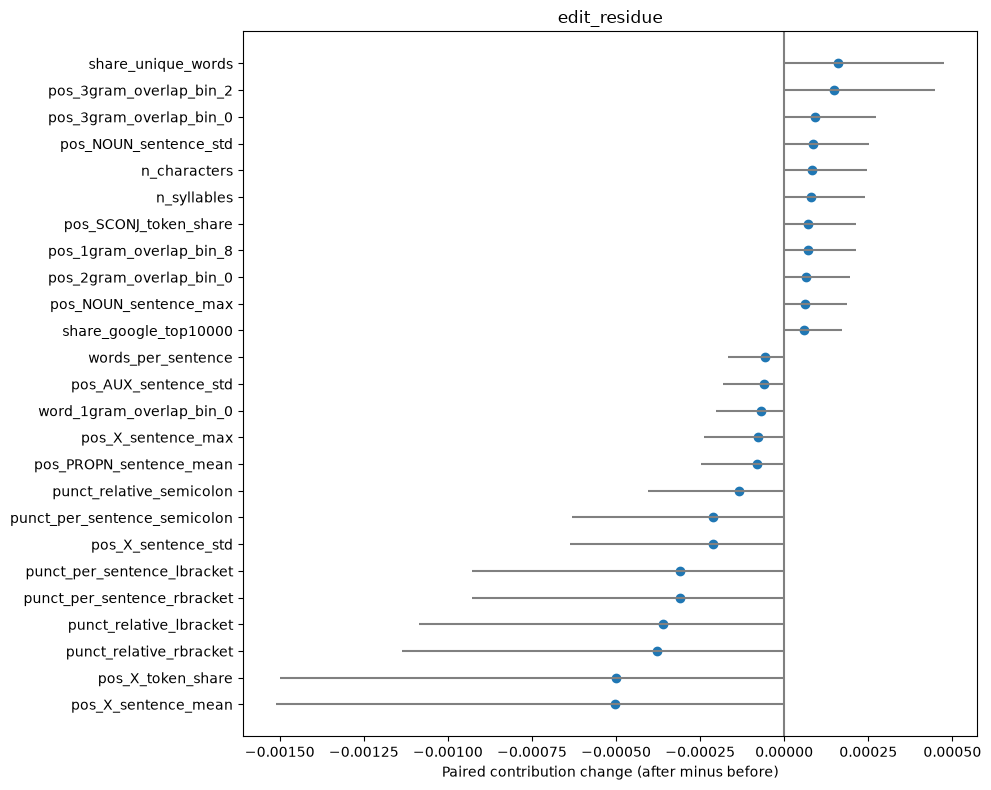

,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
182,pos_X_token_share,0.010668,0.009010,-0.001658,-0.004975,0.0
183,pos_X_sentence_mean,0.007029,0.005894,-0.001135,-0.003404,0.0
184,pos_X_sentence_std,0.005304,0.004304,-0.001001,-0.003002,0.0
185,pos_X_sentence_max,0.003347,0.002521,-0.000826,-0.002478,0.0


,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
169,pos_PUNCT_sentence_max,0.000185,0.000446,0.000261,0.0,0.000783
168,pos_PUNCT_sentence_std,0.000359,0.000496,0.000137,0.0,0.000410
166,pos_PUNCT_token_share,0.000400,0.000524,0.000124,0.0,0.000372
46,punct_per_sentence_hyphen,0.001696,0.001799,0.000102,0.0,0.000306
23,share_unique_words,0.002161,0.002219,0.000058,0.0,0.000173
29,punct_relative_colon,-0.002385,-0.002335,0.000050,0.0,0.000150
114,pos_3gram_overlap_bin_9,-0.000032,0.000012,0.000044,0.0,0.000132
67,word_2gram_overlap_bin_2,0.000009,0.000052,0.000043,0.0,0.000130
33,punct_relative_hyphen,0.001307,0.001345,0.000037,0.0,0.000112
124,pos_ADP_sentence_std,0.003226,0.003257,0.000030,0.0,0.000091


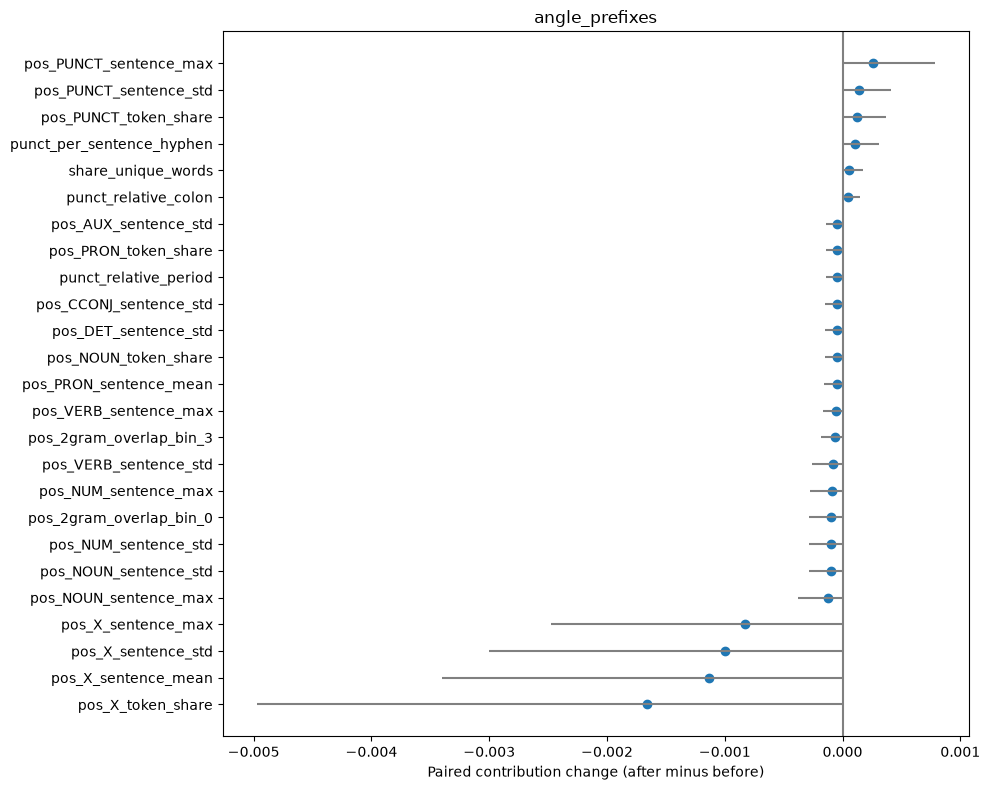

,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
182,pos_X_token_share,0.010668,0.003973,-0.006695,-0.010059,-0.003289
183,pos_X_sentence_mean,0.007029,0.002136,-0.004893,-0.007658,-0.002184
184,pos_X_sentence_std,0.005304,0.002136,-0.003168,-0.005352,-0.001286
185,pos_X_sentence_max,0.003347,0.001471,-0.001876,-0.003542,-0.000422


,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
29,punct_relative_colon,-0.002385,0.005019,0.007404,3.769477e-03,0.010976
42,punct_per_sentence_colon,-0.002341,0.003262,0.005603,3.048345e-03,0.008137
168,pos_PUNCT_sentence_std,0.000359,0.000685,0.000326,3.042400e-05,0.000646
169,pos_PUNCT_sentence_max,0.000185,0.000470,0.000285,-8.080931e-07,0.000592
23,share_unique_words,0.002161,0.002405,0.000244,6.866872e-05,0.000411
75,word_3gram_overlap_bin_0,0.000133,0.000375,0.000242,-5.915877e-06,0.000600
110,pos_3gram_overlap_bin_5,-0.000057,0.000151,0.000208,-3.790142e-05,0.000503
95,pos_2gram_overlap_bin_0,0.000337,0.000537,0.000200,3.924194e-05,0.000383
105,pos_3gram_overlap_bin_0,-0.000406,-0.000248,0.000158,-6.368221e-05,0.000427
171,pos_SCONJ_sentence_mean,-0.000940,-0.000801,0.000139,-2.818986e-05,0.000341


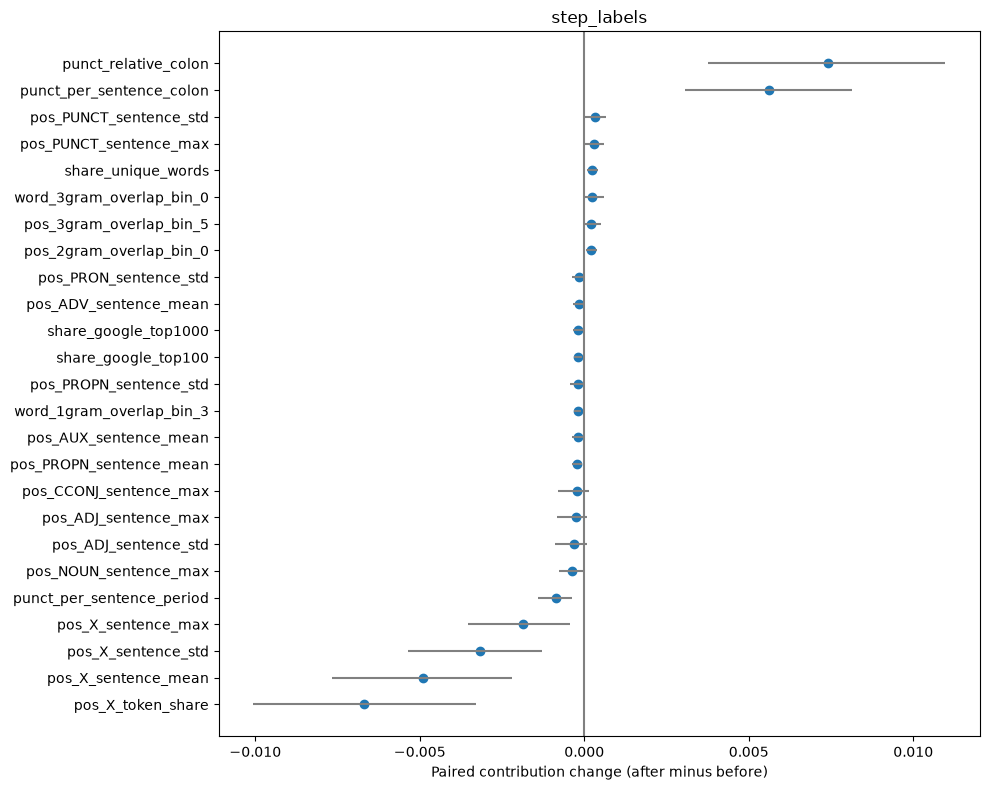

,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
182,pos_X_token_share,0.010668,0.001815,-0.008853,-0.012220,-0.005053
183,pos_X_sentence_mean,0.007029,0.000498,-0.006531,-0.009316,-0.003538
184,pos_X_sentence_std,0.005304,0.000924,-0.004381,-0.006662,-0.002161
185,pos_X_sentence_max,0.003347,0.000566,-0.002781,-0.004737,-0.001037


,feature,before_gap,after_gap,contribution_change,ci_low,ci_high
29,punct_relative_colon,-0.002385,0.005067,0.007452,3.894209e-03,0.010984
42,punct_per_sentence_colon,-0.002341,0.003249,0.005590,3.046521e-03,0.008105
169,pos_PUNCT_sentence_max,0.000185,0.000747,0.000562,1.017629e-04,0.001141
168,pos_PUNCT_sentence_std,0.000359,0.000835,0.000476,1.171382e-04,0.000828
23,share_unique_words,0.002161,0.002621,0.000460,1.745484e-04,0.000809
75,word_3gram_overlap_bin_0,0.000133,0.000379,0.000246,-7.866667e-07,0.000602
105,pos_3gram_overlap_bin_0,-0.000406,-0.000160,0.000246,-1.950301e-05,0.000556
46,punct_per_sentence_hyphen,0.001696,0.001915,0.000219,4.061113e-05,0.000452
110,pos_3gram_overlap_bin_5,-0.000057,0.000150,0.000207,-3.795347e-05,0.000502
166,pos_PUNCT_token_share,0.000400,0.000605,0.000205,-1.024529e-04,0.000516


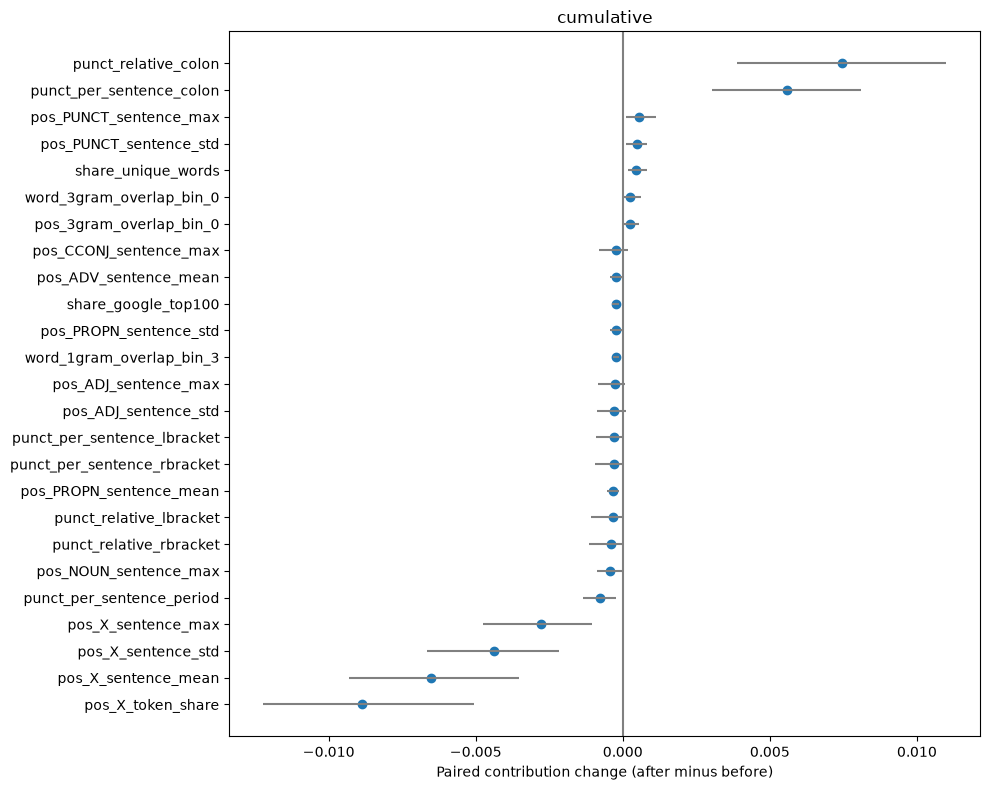

,arm,changed_cases,X_block_change,ci_low,ci_high,changed_only_X_change,mean_AI_score_before,mean_AI_score_after
0,edit_residue,1,-0.001294,-0.003883,0.00000,-0.069894,0.540866,0.538898
1,angle_prefixes,1,-0.004619,-0.013858,0.00000,-0.249450,0.540866,0.534990
2,step_labels,7,-0.016632,-0.026090,-0.00755,-0.128305,0.540866,0.534076
3,cumulative,9,-0.022546,-0.032593,-0.01174,-0.135276,0.540866,0.526232


Negative contribution change is the desired direction. Unchanged cases remain in the 54-case average.
Review displaced contributions and text_diffs.txt before adopting cumulative_texts.csv. Baseline files were not modified.
../results/causal/C03c_targeted_X_edits/43e6aea62d49


In [18]:
SEED=int(contract['seed']);B=2000;rows=[];case_rows=[]
before_scores=detector.predict_proba(BASE_X)[:,1]
for arm,texts in arms.items():
    frame=full_frame(texts);c=contributions(frame);delta=c-BASE_C;after_gap=c-REF
    changed=np.array([a!=b for a,b in zip(texts,data.text)])
    pd.DataFrame(delta,columns=COLS).assign(case_id=data.case_id.to_numpy()).to_csv(OUT/f'{arm}_contribution_deltas.csv',index=False)
    pd.DataFrame(after_gap,columns=COLS).assign(case_id=data.case_id.to_numpy()).to_csv(OUT/f'{arm}_human_adjusted_gaps.csv',index=False)
    (frame-BASE_X).assign(case_id=data.case_id.to_numpy()).to_csv(OUT/f'{arm}_feature_deltas.csv',index=False)
    rng=np.random.default_rng(SEED);boot=np.zeros((B,len(COLS)))
    for genre in sorted(data.domain.unique()):
        ix=np.flatnonzero(data.domain.eq(genre));draw=rng.choice(ix,(B,len(ix)),replace=True)
        boot+=len(ix)/len(data)*delta[draw].mean(axis=1)
    lo,hi=np.quantile(boot,[.025,.975],axis=0)
    ranking=pd.DataFrame(dict(feature=COLS,before_gap=BASE_G.mean(0),after_gap=after_gap.mean(0),contribution_change=delta.mean(0),ci_low=lo,ci_high=hi))
    ranking.to_csv(OUT/f'{arm}_all_feature_changes.csv',index=False)
    display(ranking.loc[ranking.feature.isin(XCOLS)])
    display(ranking.sort_values('contribution_change',ascending=False).head(12))
    xi=[COLS.index(f) for f in XCOLS];block=delta[:,xi].sum(1);blo,bhi=np.quantile(boot[:,xi].sum(1),[.025,.975])
    rows.append(dict(arm=arm,changed_cases=changed.sum(),X_block_change=block.mean(),ci_low=blo,ci_high=bhi,changed_only_X_change=block[changed].mean() if changed.any() else np.nan,mean_AI_score_before=before_scores.mean(),mean_AI_score_after=detector.predict_proba(frame)[:,1].mean()))
    case_rows.extend(dict(arm=arm,case_id=cid,changed=ch,X_block_change=d) for cid,ch,d in zip(data.case_id,changed,block))
    top=ranking.reindex(ranking.contribution_change.abs().sort_values(ascending=False).index).head(25).sort_values('contribution_change')
    fig,ax=plt.subplots(figsize=(10,8));y=np.arange(len(top));ax.hlines(y,top.ci_low,top.ci_high,color='gray');ax.scatter(top.contribution_change,y);ax.set_yticks(y,top.feature);ax.axvline(0,color='gray');ax.set_xlabel('Paired contribution change (after minus before)');ax.set_title(arm)
    fig.tight_layout()
    for folder in (OUT,FIG):
        for ext in ('pdf','png'):fig.savefig(folder/f'C03c_{arm}_changes.{ext}',bbox_inches='tight',dpi=300)
    plt.show()
summary=pd.DataFrame(rows);summary.to_csv(OUT/'summary.csv',index=False);pd.DataFrame(case_rows).to_csv(OUT/'case_X_changes.csv',index=False);display(summary)
print('Negative contribution change is the desired direction. Unchanged cases remain in the 54-case average.')
print('Review displaced contributions and text_diffs.txt before adopting cumulative_texts.csv. Baseline files were not modified.')
print(OUT)


In [19]:
# Step 5.5 — reuse C02 colon/comma controls after C03c.
import ast
import copy
import math
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM

c02_path = ROOT / "experiments/C02w0_complete_missing27.ipynb"
notebook = json.loads(c02_path.read_text())

sources = [
    "".join(c["source"]) if isinstance(c["source"], list) else c["source"]
    for c in notebook["cells"] if c["cell_type"] == "code"
]

# Isolated globals: C02's language model must not replace FZ186.
ns = dict(
    np=np, pd=pd, re=re, json=json, hashlib=hashlib,
    math=math, copy=copy, torch=torch,
    Counter=Counter, lru_cache=lru_cache,
    nlp=nlp, normalize=normalize,
)

# Import actual function definitions only; do not execute C02's pipeline.
wanted = {
    "measure", "stats_for", "continuation_score", "score_edit",
    "independent", "stable_rng", "rates", "outside", "vertices",
    "mark_loss", "enforce", "rebuild_targets", "punctuation_spec",
}
loaded = set()
for source in sources:
    for node in ast.parse(source).body:
        if isinstance(node, ast.FunctionDef):
            # First score_edit is the implementation; the later one is
            # only a progress-reporting wrapper.
            if node.name in wanted and node.name not in loaded:
                module = ast.Module(body=[node], type_ignores=[])
                exec(compile(module, str(c02_path), "exec"), ns)
                loaded.add(node.name)
assert loaded == wanted, f"Missing C02 functions: {wanted - loaded}"

parent_dir = ROOT / "results/causal/C02r_discovery_gated_punctuation"
treatment = json.loads((parent_dir / "treatment_contract.json").read_text())
gate = json.loads((parent_dir / "frozen_punctuation_gate.json").read_text())

features55 = pd.read_parquet(BASE / "fz118_paired_features.parquet")
corpus55 = pd.read_parquet(BASE / "paired_corpus.parquet")
text_map55 = corpus55.set_index("source_id").text.to_dict()
human_train55 = features55.loc[
    features55.dataset.eq("raid")
    & features55.split.eq("train")
    & features55.label.eq(0)
]

# Preserve C02's denominator choices and explicitly enforce colon then comma.
active55 = {
    mark: list(gate["active_denominators"].get(mark, []))
    for mark in ("colon", "comma")
}
assert all(active55.values()), (
    f"C02 frozen gate does not activate both requested marks: {active55}"
)

ns.update(
    SELECTION_SEED=20260906,
    BOOTSTRAPS=3000,
    ARTIFICIAL_SD_SCALE=0.5,
    BUMP_P_MIN=0.10,
    MEAN_DISTANCE_TOLERANCE={"wps_mean": 0.5, "cps_mean": 3.0},
    SENT_METRICS=["wps_mean", "cps_mean"],
    PMARKS={
        "semicolon": ";", "colon": ":", "hyphen": "-",
        "en_dash": "–", "em_dash": "—", "comma": ",",
    },
    DENOMS=["relative", "per_sentence"],
    active=active55,
    LEFT_WORDS=48,
    RIGHT_WORDS=32,
    text_map=text_map55,
    compound_examples={},
)

# Recover previously frozen reference IDs and sentence bounds.
refs55 = {
    r["case_id"]: r for r in treatment["prepared"]
}
missing55 = set(data.case_id) - set(refs55)
policy_paths = []
if missing55:
    candidates = sorted(
        (ROOT / "results/causal").glob(
            "C02w0_complete_missing27*/reference_policy.csv"
        )
    )
    for path in candidates:
        policy = pd.read_csv(path, keep_default_na=False)
        used = False
        for r in policy.itertuples():
            if r.case_id not in missing55:
                continue
            record = {
                "reference_ids": json.loads(r.reference_ids),
                "bounds": json.loads(r.bounds),
            }
            if r.case_id in refs55:
                assert refs55[r.case_id] == record, (
                    f"Conflicting completion reference policies: {r.case_id}"
                )
            refs55[r.case_id] = record
            used = True
        if used:
            policy_paths.append(path)

assert set(data.case_id) <= set(refs55), "Missing saved C02 reference policies"

cases55 = {}
for r in data.itertuples():
    ref = refs55[r.case_id]
    allowed = set(
        human_train55.loc[
            human_train55.domain.eq(r.domain), "source_id"
        ]
    )
    assert len(ref["reference_ids"]) >= 15
    assert set(ref["reference_ids"]) <= allowed
    cases55[r.case_id] = dict(
        case_id=r.case_id, source_id=r.source_id, domain=r.domain,
        reference_ids=ref["reference_ids"], bounds=ref["bounds"],
    )

# Recreate genre reference statistics using C02's exact code and RNG policy.
# This section computes reference statistics; it does not modify texts.
reference_source = next(
    s for s in sources
    if "genre_ref={}" in s and "compound_examples={}" in s
)
reference_block = reference_source[
    reference_source.index("training=features.loc"):
    reference_source.index("compound_examples={}")
]
ns["features"] = features55
ns["evaluation"] = [(c, {}) for c in cases55.values()]
exec(compile(reference_block, str(c02_path), "exec"), ns)

# Narrow extension: step-label colons are formatting separators.
original_vertices55 = ns["vertices"]

def vertices55(text, mark, genre):
    labels = {
        m.end() - 1
        for m in re.finditer(r"\bStep\s+\d{1,2}:", text)
    } if genre == "recipes" else set()

    for edit in original_vertices55(text, mark, genre):
        if mark == "colon" and any(
            edit["start"] <= pos < edit["end"] for pos in labels
        ):
            continue
        yield edit

    if mark == "colon":
        for pos in sorted(labels):
            end = pos + 1
            while end < len(text) and text[end] in " \t":
                end += 1
            yield dict(start=pos, end=end, replacement=" ")

ns["vertices"] = vertices55

scorer_id = treatment["scorer"]
revision = treatment["scorer_revision"]
assert revision and revision != "main"

ns["tokenizer"] = AutoTokenizer.from_pretrained(
    scorer_id, revision=revision, use_fast=True
)
ns["model"] = AutoModelForCausalLM.from_pretrained(
    scorer_id, revision=revision
)
ns["device"] = "cuda" if torch.cuda.is_available() else "cpu"
ns["model"].to(ns["device"]).eval()

input55 = OUT / "cumulative_texts.csv"
frame55 = pd.read_csv(input55, keep_default_na=False)
frame55 = frame55.set_index("case_id").loc[data.case_id].reset_index()

assert frame55.source_id.tolist() == data.source_id.tolist()
assert frame55.domain.tolist() == data.domain.tolist()

spec55 = dict(
    parent_c03c=str(OUT),
    input_sha=hashlib.sha256(input55.read_bytes()).hexdigest(),
    c02_sha=hashlib.sha256(c02_path.read_bytes()).hexdigest(),
    treatment_sha=hashlib.sha256(
        (parent_dir / "treatment_contract.json").read_bytes()
    ).hexdigest(),
    gate=gate,
    references=cases55,
    order=["colon", "comma"],
    extension="Step-number-colon to space v1",
    target_policy="C02 reference bands; rebuild exposure-dependent targets",
    scorer=scorer_id,
    revision=revision,
)
key55 = hashlib.sha256(
    json.dumps(spec55, sort_keys=True).encode()
).hexdigest()[:12]
out55 = OUT / f"step55_{key55}"
out55.mkdir(exist_ok=True)
(out55 / "contract.json").write_text(json.dumps(spec55, indent=2))

colon_texts55, final_texts55, edits55 = [], [], []

for r in frame55.itertuples():
    checkpoint = out55 / f"{r.case_id}.json"

    if checkpoint.exists():
        result = json.loads(checkpoint.read_text())
    else:
        # One specification for both passes keeps the assigned targets fixed.
        p = ns["punctuation_spec"](cases55[r.case_id], r.text)
        result = ns["enforce"](p)
        tmp = checkpoint.with_suffix(".tmp")
        tmp.write_text(json.dumps(result, indent=2, ensure_ascii=False))
        tmp.replace(checkpoint)

    # enforce processes colon first, then comma. Recover the intermediate.
    colon_text = r.text
    for edit in result["edits"]:
        if edit["mark"] == "colon":
            colon_text = edit["after"]
        edits55.append({"case_id": r.case_id, **edit})

    colon_texts55.append(colon_text)
    final_texts55.append(result["text"])

for stage, texts in [
    ("after_colon", colon_texts55),
    ("after_comma", final_texts55),
]:
    exported = frame55.copy()
    exported["text"] = texts
    exported["provenance"] = str(
        (out55 / f"{stage}_texts.csv").relative_to(ROOT)
    )
    exported.to_csv(out55 / f"{stage}_texts.csv", index=False)

pd.DataFrame(edits55).to_csv(out55 / "edits.csv", index=False)
with (out55 / "text_diffs.txt").open("w") as f:
    for cid, before, colon, after in zip(
        data.case_id, frame55.text, colon_texts55, final_texts55
    ):
        if before != after:
            f.write(
                f"\n{cid}\nAFTER STEP 5:\n{before}\n"
                f"AFTER COLON:\n{colon}\nAFTER COMMA:\n{after}\n"
            )

# Release GPT-2; retain the frozen FZ186 in the notebook's main namespace.
del ns["model"], ns["tokenizer"]
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Same FZ186, same fixed human references, all 54 cases.
stages55 = {
    "before_step5": data.text.tolist(),
    "after_step5": frame55.text.tolist(),
    "after_colon": colon_texts55,
    "after_step55": final_texts55,
}
tracked55 = XCOLS + [
    "punct_relative_colon", "punct_per_sentence_colon",
    "punct_relative_comma", "punct_per_sentence_comma",
]
contrib55, rows55 = {}, []

for stage, texts in stages55.items():
    x = full_frame(texts)
    c = contributions(x)
    contrib55[stage] = c
    gaps = c - REF

    pd.DataFrame(gaps, columns=COLS).assign(
        case_id=data.case_id.to_numpy()
    ).to_csv(out55 / f"{stage}_contribution_gaps.csv", index=False)

    row = {"stage": stage}
    row.update({
        feature: gaps[:, COLS.index(feature)].mean()
        for feature in tracked55
    })
    row["X_block_gap"] = gaps[:, [COLS.index(f) for f in XCOLS]].sum(1).mean()
    row["mean_AI_score"] = detector.predict_proba(x)[:, 1].mean()
    rows55.append(row)

table55 = pd.DataFrame(rows55).set_index("stage")
table55.to_csv(out55 / "stage_summary.csv")
display(table55)

# Report every feature's change during punctuation cleanup.
delta55 = contrib55["after_step55"] - contrib55["after_step5"]
pd.DataFrame(delta55, columns=COLS).assign(
    case_id=data.case_id.to_numpy()
).to_csv(out55 / "step55_case_contribution_changes.csv", index=False)

change55 = pd.DataFrame({
    "feature": COLS,
    "mean_contribution_change": delta55.mean(0),
}).sort_values("mean_contribution_change", ascending=False)
change55.to_csv(out55 / "step55_all_feature_changes.csv", index=False)
display(change55.head(15))

fig, ax = plt.subplots(figsize=(11, 6))
table55[tracked55].T.plot.barh(ax=ax)
ax.axvline(0, color="gray", linewidth=1)
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_ylabel("")
fig.tight_layout()
for folder in (out55, FIG):
    for ext in ("pdf", "png"):
        fig.savefig(
            folder / f"C03c_step55_contributions.{ext}",
            dpi=300, bbox_inches="tight",
        )
plt.show()

print("Saved:", out55)
print("Check that colon/comma repair retains the X contribution reduction.")

/home/user/Downloads/TemporalContextResearch/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


KeyboardInterrupt: 

In [ ]:
from sklearn.metrics import roc_curve, auc

# Final step-5.5 texts; preserve the original case ordering.
final_eval = pd.read_csv(
    out55 / "after_comma_texts.csv", keep_default_na=False
).set_index("case_id").loc[data.case_id].reset_index()

assert final_eval.source_id.tolist() == data.source_id.tolist()
assert final_eval.domain.tolist() == data.domain.tolist()
assert list(detector.feature_names_in_) == COLS

X_final = full_frame(final_eval.text.tolist())
scores_final = detector.predict_proba(X_final)[:, 1]
scores_before = detector.predict_proba(BASE_X)[:, 1]

# Reuse C03's exact calibration/test humans and their genre weights.
def load_humans(stage):
    manifest_h = pd.read_csv(
        RUN_DIR / f"human_{stage}_manifest.csv"
    )
    assert manifest_h.source_id.is_unique
    texts = [text_map55[sid] for sid in manifest_h.source_id]
    matrix = full_frame(texts)
    weights = manifest_h.weight.to_numpy(float)
    assert np.isclose(weights.sum(), 1.0)
    return detector.predict_proba(matrix)[:, 1], weights

cal_scores, cal_weights = load_humans("calibration")
human_scores, human_weights = load_humans("test")

# Same strict score > threshold rule used by C03.
cuts = np.r_[np.inf, np.unique(cal_scores)[::-1], -np.inf]
cal_fpr = np.array([
    cal_weights[cal_scores > cut].sum() for cut in cuts
])

staircase = []
for budget in [0.01, 0.05, 0.10, 0.20, 0.30, 0.50, 1.00]:
    j = np.flatnonzero(cal_fpr <= budget + 1e-12)[-1]
    threshold = cuts[j]
    staircase.append({
        "requested_FPR": budget,
        "calibration_FPR": cal_fpr[j],
        "test_FPR": human_weights[human_scores > threshold].sum(),
        "threshold": threshold,
        "Before_step5_TPR": (scores_before > threshold).mean(),
        "After_step55_TPR": (scores_final > threshold).mean(),
        "Before_detected": int((scores_before > threshold).sum()),
        "After_detected": int((scores_final > threshold).sum()),
        "n_AI": len(final_eval),
    })

staircase = pd.DataFrame(staircase)
staircase.to_csv(out55 / "final_TPR_staircase.csv", index=False)
display(staircase)

def save_final_figure(fig, stem):
    fig.tight_layout()
    for folder in (out55, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(
                folder / f"{stem}.{ext}",
                dpi=300, bbox_inches="tight",
            )
    plt.show()

# Full empirical ROC staircase, plus low-FPR view.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
roc_rows, auc_rows = [], []
for label, ai_scores in [
    ("Before step 5", scores_before),
    ("After step 5.5", scores_final),
]:
    fpr, tpr, thresholds = roc_curve(
        np.r_[np.zeros(len(human_scores)), np.ones(len(ai_scores))],
        np.r_[human_scores, ai_scores],
        sample_weight=np.r_[
            human_weights, np.ones(len(ai_scores)) / len(ai_scores)
        ],
        drop_intermediate=False,
    )
    area = auc(fpr, tpr)
    auc_rows.append({
        "stage": label, "AUC": area,
        "mean_AI_score": ai_scores.mean(),
    })
    roc_rows.extend(
        {"stage": label, "FPR": x, "TPR": y}
        for x, y in zip(fpr, tpr)
    )
    for ax in axes:
        ax.step(fpr, tpr, where="post", label=f"{label} ({area:.3f})")

for ax in axes:
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(xlabel="Genre-weighted test human FPR", ylabel="AI TPR")
    ax.legend()
axes[1].set_xlim(0, 0.20)
save_final_figure(fig, "C03c_step55_final_ROC")

pd.DataFrame(roc_rows).to_csv(out55 / "final_ROC_points.csv", index=False)
pd.DataFrame(auc_rows).to_csv(out55 / "final_AUC_summary.csv", index=False)
display(pd.DataFrame(auc_rows))

# Contributions against the SAME fixed human references.
final_c = contributions(X_final)
final_gap = final_c - REF
before_gap = BASE_C - REF

# Paired bootstrap within AI genres; human references remain fixed.
B_final = 2000
rng = np.random.default_rng(int(contract["seed"]))
boot_gap = np.zeros((B_final, len(COLS)))
boot_change = np.zeros_like(boot_gap)

for genre in sorted(data.domain.unique()):
    ix = np.flatnonzero(data.domain.eq(genre))
    draws = rng.choice(ix, size=(B_final, len(ix)), replace=True)
    weight = len(ix) / len(data)
    boot_gap += weight * final_gap[draws].mean(axis=1)
    boot_change += weight * (
        final_gap[draws] - before_gap[draws]
    ).mean(axis=1)

lo, hi = np.quantile(boot_gap, [0.025, 0.975], axis=0)
dlo, dhi = np.quantile(boot_change, [0.025, 0.975], axis=0)

ranking = pd.DataFrame({
    "feature": COLS,
    "raw_mean_contribution": final_c.mean(axis=0),
    "before_gap": before_gap.mean(axis=0),
    "human_adjusted_gap": final_gap.mean(axis=0),
    "ci_low": lo,
    "ci_high": hi,
    "contribution_change": (final_gap - before_gap).mean(axis=0),
    "change_ci_low": dlo,
    "change_ci_high": dhi,
    "fraction_AI_directed": (final_gap > 0).mean(axis=0),
}).sort_values("human_adjusted_gap", ascending=False)

ranking.to_csv(out55 / "final_contribution_ranking.csv", index=False)
pd.DataFrame(final_gap, columns=COLS).assign(
    case_id=data.case_id.to_numpy()
).to_csv(out55 / "final_case_contribution_gaps.csv", index=False)

display(ranking.head(30))

top = ranking.head(30).iloc[::-1]
y = np.arange(len(top))
fig, ax = plt.subplots(figsize=(11, 10))
ax.hlines(y, top.ci_low, top.ci_high, color="gray", alpha=0.65)
ax.scatter(
    top.before_gap, y, color="tab:blue",
    label="Before step 5", s=28,
)
ax.scatter(
    top.human_adjusted_gap, y, color="tab:orange",
    label="After step 5.5", s=32,
)
ax.set_yticks(y, top.feature)
ax.axvline(0, color="gray")
ax.set_xlabel("Mean contribution minus fixed same-genre human reference")
ax.set_title("Frozen FZ186 — top 30 remaining AI-directed contributions")
ax.legend()
save_final_figure(fig, "C03c_step55_final_contributions")

final_eval[["case_id", "source_id", "domain"]].assign(
    before_score=scores_before,
    final_score=scores_final,
).to_csv(out55 / "final_case_scores.csv", index=False)

print("Saved results:", out55)

In [ ]:
# C03d — ADV / NUM / ADP audit on post-5.5 texts.
TAGS = ["ADV", "NUM", "ADP"]
STATS = ["token_share", "sentence_mean", "sentence_std", "sentence_max"]
audit_dir = out55 / "ADV_NUM_ADP_audit"
audit_dir.mkdir(exist_ok=True)

human_manifest = pd.read_csv(RUN_DIR / "human_test_manifest.csv")
mix = data.domain.value_counts(normalize=True)

specs = [
    dict(group="Fixed AI", case_id=r.case_id, source_id=r.source_id,
         domain=r.domain, text=r.text)
    for r in final_eval.itertuples()
] + [
    dict(group="Human", case_id=str(r.source_id), source_id=r.source_id,
         domain=r.domain, text=text_map55[r.source_id])
    for r in human_manifest.itertuples()
]

document_rows, sentence_rows, token_rows = [], [], []

for spec, doc in zip(
    specs,
    nlp.pipe([normalize(s["text"]) for s in specs], batch_size=32),
):
    meta = {k: spec[k] for k in ("group", "case_id", "source_id", "domain")}
    sentences = [
        s for s in doc.sents if any(not t.is_space for t in s)
    ]
    tokens = [t for t in doc if not t.is_space]

    for tag in TAGS:
        counts = np.array([
            sum(t.pos_ == tag for t in s if not t.is_space)
            for s in sentences
        ], dtype=float)

        document_rows.append({
            **meta, "tag": tag,
            "n_tokens": len(tokens),
            "n_sentences": len(sentences),
            "tokens_per_sentence": len(tokens) / max(1, len(sentences)),
            "token_share": sum(t.pos_ == tag for t in tokens)
                           / max(1, len(tokens)),
            "sentence_mean": counts.mean() if len(counts) else 0.,
            "sentence_std": counts.std() if len(counts) else 0.,
            "sentence_max": counts.max() if len(counts) else 0.,
        })

        for j, sent in enumerate(sentences):
            selected = [t for t in sent if t.pos_ == tag]
            sent_length = sum(not t.is_space for t in sent)

            # Mark occurrences using offsets, preserving the actual sentence.
            marked = sent.text
            for t in reversed(selected):
                a = t.idx - sent.start_char
                b = a + len(t.text)
                marked = marked[:a] + "⟦" + marked[a:b] + "⟧" + marked[b:]

            sentence_rows.append({
                **meta, "tag": tag, "sentence_index": j,
                "count": len(selected), "sentence_tokens": sent_length,
                "share": len(selected) / max(1, sent_length),
                "sentence": sent.text, "highlighted": marked,
            })

            for t in selected:
                # Structural description, not an automatic semantic judgment.
                prefix = doc.text[max(0, t.idx - 20):t.idx]
                role = t.dep_
                if tag == "NUM" and re.search(r"\bstep\s*$", prefix, re.I):
                    role = "step_label_candidate"

                token_rows.append({
                    **meta, "tag": tag,
                    "token": t.text, "lemma": t.lemma_.lower(),
                    "fine_tag": t.tag_, "dependency": t.dep_,
                    "role": role, "head": t.head.text,
                    "head_pos": t.head.pos_,
                    "sentence_index": j,
                    "sentence": sent.text,
                })

doc_audit = pd.DataFrame(document_rows)
sent_audit = pd.DataFrame(sentence_rows)
tok_audit = pd.DataFrame(token_rows)

doc_audit.to_csv(audit_dir / "document_statistics.csv", index=False)
sent_audit.to_csv(audit_dir / "sentence_contexts.csv", index=False)
tok_audit.to_csv(audit_dir / "token_contexts.csv", index=False)

# Confirm that the audit reproduces the detector's feature definitions.
for tag in TAGS:
    subset = doc_audit.loc[
        doc_audit.group.eq("Fixed AI") & doc_audit.tag.eq(tag)
    ].set_index("case_id").loc[final_eval.case_id]
    for stat in STATS:
        np.testing.assert_allclose(
            subset[stat].to_numpy(),
            X_final[f"pos_{tag}_{stat}"].to_numpy(),
            atol=1e-10, rtol=0,
        )

# Human comparisons use the same genre mixture as the 54 AI texts.
summary_rows = []
for (group, genre, tag), subset in doc_audit.groupby(
    ["group", "domain", "tag"]
):
    for stat in STATS:
        summary_rows.append({
            "group": group, "domain": genre, "tag": tag,
            "statistic": stat, "documents": len(subset),
            "mean": subset[stat].mean(),
            "median": subset[stat].median(),
            "q10": subset[stat].quantile(.10),
            "q90": subset[stat].quantile(.90),
        })

genre_summary = pd.DataFrame(summary_rows)
genre_summary.to_csv(audit_dir / "statistics_by_genre.csv", index=False)

weighted_rows = []
for (group, tag, stat), subset in genre_summary.groupby(
    ["group", "tag", "statistic"]
):
    assert set(mix.index) <= set(subset.domain)
    weighted_rows.append({
        "group": group, "tag": tag, "statistic": stat,
        "weighted_mean": np.sum(subset.domain.map(mix) * subset["mean"]),
    })

weighted_summary = pd.DataFrame(weighted_rows)
weighted_summary.to_csv(audit_dir / "weighted_statistics.csv", index=False)
display(weighted_summary.pivot(
    index=["tag", "statistic"], columns="group", values="weighted_mean"
))

# Frequent lemmas and grammatical roles.
# Count per document first, so zero-occurrence documents enter denominators.
def frequency_table(key):
    counts = tok_audit.groupby(
        ["group", "domain", "tag", "case_id", key]
    ).size().rename("count").reset_index()

    denominators = doc_audit[
        ["group", "domain", "tag", "case_id", "n_tokens"]
    ]
    counts = counts.merge(
        denominators,
        on=["group", "domain", "tag", "case_id"],
        validate="many_to_one",
    )
    counts["per_1000"] = 1000 * counts["count"] / counts.n_tokens

    totals = doc_audit.groupby(
        ["group", "domain", "tag"]
    ).size().rename("n_documents")

    by_genre = counts.groupby(
        ["group", "domain", "tag", key]
    ).agg(
        token_count=("count", "sum"),
        documents_with=("case_id", "nunique"),
        rate_sum=("per_1000", "sum"),
    ).reset_index().merge(
        totals.reset_index(), on=["group", "domain", "tag"]
    )
    by_genre["weighted_rate"] = (
        by_genre.rate_sum / by_genre.n_documents
        * by_genre.domain.map(mix)
    )
    by_genre["weighted_prevalence"] = (
        by_genre.documents_with / by_genre.n_documents
        * by_genre.domain.map(mix)
    )

    result = by_genre.groupby(["group", "tag", key]).agg(
        token_count=("token_count", "sum"),
        documents_with=("documents_with", "sum"),
        weighted_per_1000=("weighted_rate", "sum"),
        weighted_prevalence=("weighted_prevalence", "sum"),
    ).reset_index()
    return result

for key in ["lemma", "role"]:
    frequencies = frequency_table(key)
    frequencies.to_csv(audit_dir / f"{key}_frequencies.csv", index=False)
    for tag in TAGS:
        print(f"\n{tag}: {key}")
        comparison = frequencies.loc[frequencies.tag.eq(tag)].pivot(
            index=key, columns="group", values="weighted_per_1000"
        ).fillna(0)
        comparison["AI_minus_human"] = (
            comparison["Fixed AI"] - comparison["Human"]
        )
        display(comparison.sort_values(
            "AI_minus_human", ascending=False
        ).head(20))
        print("Most human-enriched:")
        display(comparison.sort_values("AI_minus_human").head(10))

# Print one maximum-count sentence per document, including its length.
# Full sentence/context tables are saved above.
for tag in TAGS:
    for group in ["Fixed AI", "Human"]:
        subset = sent_audit.loc[
            sent_audit.tag.eq(tag) & sent_audit.group.eq(group)
        ]
        peaks = (
            subset.sort_values(
                ["count", "sentence_tokens"], ascending=False
            )
            .drop_duplicates("case_id")
            .head(10)
        )
        print(f"\n{group} — {tag}: highest-count sentences")
        for r in peaks.itertuples():
            print(
                f"{r.case_id} [{r.domain}] "
                f"{r.count} {tag} / {r.sentence_tokens} tokens\n"
                f"{r.highlighted}\n"
            )

# Plots: raw distributions and raw values versus document contributions.
# Contributions are document-level, not token-level attributions.
gap_df = pd.DataFrame(
    final_gap, columns=COLS, index=final_eval.case_id
)

def save_pos_audit(fig, stem):
    fig.tight_layout()
    for folder in (audit_dir, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(
                folder / f"C03d_{stem}.{ext}",
                dpi=300, bbox_inches="tight",
            )
    plt.show()

fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for i, tag in enumerate(TAGS):
    for j, stat in enumerate(STATS):
        ax = axes[i, j]
        for group in ["Fixed AI", "Human"]:
            subset = doc_audit.loc[
                doc_audit.tag.eq(tag) & doc_audit.group.eq(group)
            ].copy()
            counts = subset.domain.value_counts()
            subset["weight"] = [
                mix[g] / counts[g] for g in subset.domain
            ]
            # Aggregate ties for a proper empirical CDF.
            curve = subset.groupby(stat).weight.sum().sort_index().cumsum()
            ax.step(curve.index, curve.values, where="post", label=group)
        ax.set(title=f"{tag}: {stat}", ylabel="Weighted cumulative fraction")
axes[0, 0].legend()
save_pos_audit(fig, "POS_distributions")

fig, axes = plt.subplots(3, 4, figsize=(17, 10))
association_rows = []
for i, tag in enumerate(TAGS):
    subset = doc_audit.loc[
        doc_audit.tag.eq(tag) & doc_audit.group.eq("Fixed AI")
    ].set_index("case_id").loc[final_eval.case_id]
    for j, stat in enumerate(STATS):
        feature = f"pos_{tag}_{stat}"
        x = subset[stat].to_numpy()
        y = gap_df[feature].to_numpy()
        ax = axes[i, j]
        ax.scatter(x, y, alpha=.65)
        ax.axhline(0, color="gray", linewidth=1)
        ax.set(title=feature, xlabel="Raw feature value",
               ylabel="Human-adjusted contribution")
        association_rows.extend({
            "case_id": cid, "feature": feature,
            "raw_value": a, "contribution_gap": b,
        } for cid, a, b in zip(final_eval.case_id, x, y))

pd.DataFrame(association_rows).to_csv(
    audit_dir / "values_and_contributions.csv", index=False
)
save_pos_audit(fig, "POS_values_vs_contributions")

print("Saved:", audit_dir)

In [ ]:
# C03e — ADV phrase-substitution pilot.
# Each candidate is evaluated independently against the post-5.5 baseline.
pilot_dir = out55 / "ADV_substitution_pilot"
pilot_dir.mkdir(exist_ok=True)

# Deliberately narrow candidates. Contextual equivalence still needs review.
ADV_RULES = [
    ("careful_manner", r"\bin a careful manner\b", "carefully"),
    ("gradual_manner", r"\bin a gradual manner\b", "gradually"),
    ("systematic_manner", r"\bin a systematic manner\b", "systematically"),
    ("consistent_manner", r"\bin a consistent manner\b", "consistently"),
    ("effective_manner", r"\bin an effective manner\b", "effectively"),
    ("efficient_manner", r"\bin an efficient manner\b", "efficiently"),
    ("successful_manner", r"\bin a successful manner\b", "successfully"),
    ("independent_manner", r"\bin an independent manner\b", "independently"),
    ("regular_basis", r"\bon a regular basis\b", "regularly"),
    ("daily_basis", r"\bon a daily basis\b", "daily"),
    ("weekly_basis", r"\bon a weekly basis\b", "weekly"),
    ("simultaneous", r"\bsimultaneously\b", "at the same time"),
]
# The last rule is a diagnostic contrast: retagging determines its ADV effect.

adv_cols = [f"pos_ADV_{s}" for s in STATS]
adv_ix = [COLS.index(f) for f in adv_cols]
adp_ix = [COLS.index(f"pos_ADP_{s}") for s in STATS]
num_ix = [COLS.index(f"pos_NUM_{s}") for s in STATS]
x_ix = [COLS.index(f) for f in XCOLS]

baseline_texts = final_eval.text.tolist()
baseline_features = full_frame(baseline_texts)
baseline_contrib = contributions(baseline_features)
baseline_scores = detector.predict_proba(baseline_features)[:, 1]

def adv_count(text):
    return sum(t.pos_ == "ADV" for t in nlp(normalize(text)))

def preserve_case(old, replacement):
    return replacement[:1].upper() + replacement[1:] if old[:1].isupper() else replacement

candidates = []
for i, row in enumerate(final_eval.itertuples()):
    text = row.text
    before_doc = nlp(normalize(text))
    sentences = list(before_doc.sents)

    for rule, pattern, replacement in ADV_RULES:
        for match in re.finditer(pattern, text, flags=re.I):
            repl = preserve_case(match.group(), replacement)
            after = text[:match.start()] + repl + text[match.end():]
            context = next(
                (s.text for s in sentences
                 if s.start_char <= match.start() < s.end_char),
                text,
            )
            candidates.append({
                "row_index": i,
                "case_id": row.case_id,
                "domain": row.domain,
                "rule": rule,
                "start": match.start(),
                "end": match.end(),
                "old_phrase": match.group(),
                "replacement": repl,
                "context": context,
                "before": text,
                "after": after,
            })

if not candidates:
    print(
        "No eligible phrases found. This is a coverage result, "
        "not evidence that ADV substitutions are ineffective."
    )
    pd.DataFrame(columns=[
        "case_id", "rule", "before", "after"
    ]).to_csv(pilot_dir / "candidates.csv", index=False)

else:
    candidate_features = full_frame([c["after"] for c in candidates])
    candidate_contrib = contributions(candidate_features)
    candidate_scores = detector.predict_proba(candidate_features)[:, 1]

    rows = []
    for j, candidate in enumerate(candidates):
        i = candidate["row_index"]
        delta = candidate_contrib[j] - baseline_contrib[i]
        before_adv = adv_count(candidate["before"])
        after_adv = adv_count(candidate["after"])

        result = {
            **candidate,
            "ADV_count_before": before_adv,
            "ADV_count_after": after_adv,
            "ADV_count_change": after_adv - before_adv,
            # Negative change means reduced AI-directed contribution.
            "ADV_contribution_change": delta[adv_ix].sum(),
            "ADP_contribution_change": delta[adp_ix].sum(),
            "NUM_contribution_change": delta[num_ix].sum(),
            "X_contribution_change": delta[x_ix].sum(),
            "other_features_change": delta.sum() - delta[adv_ix].sum(),
            "AI_score_before": baseline_scores[i],
            "AI_score_after": candidate_scores[j],
            "fidelity_review": "",
            "grammar_review": "",
            "notes": "",
        }
        for feature in adv_cols:
            k = COLS.index(feature)
            result[feature + "_before"] = baseline_features.iloc[i][feature]
            result[feature + "_after"] = candidate_features.iloc[j][feature]
            result[feature + "_contribution_change"] = delta[k]
        rows.append(result)

    results = pd.DataFrame(rows).sort_values("ADV_contribution_change")
    results.to_csv(pilot_dir / "candidates.csv", index=False)

    # Save the full contribution change vector for each candidate.
    indices = [c["row_index"] for c in candidates]
    all_changes = pd.DataFrame(
        candidate_contrib - baseline_contrib[indices], columns=COLS
    )
    all_changes.insert(0, "case_id", [c["case_id"] for c in candidates])
    all_changes.insert(1, "rule", [c["rule"] for c in candidates])
    all_changes.insert(2, "start", [c["start"] for c in candidates])
    all_changes.to_csv(pilot_dir / "all_feature_changes.csv", index=False)

    display(results[[
        "case_id", "rule", "old_phrase", "replacement",
        "ADV_count_change", "ADV_contribution_change",
        "ADP_contribution_change", "X_contribution_change",
        "other_features_change",
    ]])

    for row in results.itertuples():
        print(
            f"\n{row.case_id} — {row.rule}\n"
            f"Context: {row.context}\n"
            f"Swap: {row.old_phrase!r} → {row.replacement!r}\n"
            f"ADV contribution change: {row.ADV_contribution_change:+.6f}"
        )

    # Candidate-level diagnostic, not a cohort treatment estimate.
    shown = results.head(25).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, max(4, len(shown) * .35)))
    labels = [
        f"{r.case_id}: {r.old_phrase} → {r.replacement}"
        for r in shown.itertuples()
    ]
    ax.barh(labels, shown.ADV_contribution_change)
    ax.axvline(0, color="gray")
    ax.set_xlabel("ADV contribution change per candidate (after − before)")
    ax.set_title("Independent ADV substitution candidates")
    fig.tight_layout()

    for folder in (pilot_dir, FIG):
        for ext in ("pdf", "png"):
            fig.savefig(
                folder / f"C03e_ADV_candidates.{ext}",
                dpi=300, bbox_inches="tight",
            )
    plt.show()

    print(
        "Candidates are independent: their effects must not be summed "
        "as if they were a combined intervention."
    )

print("Saved:", pilot_dir)

In [ ]:
# # Run once before the PPDB ADV cell. Downloads 2.26 GB; no additional packages.
# from pathlib import Path
# import urllib.request, hashlib, gzip, json, time

# PPDB_PATH = Path(ROOT) / 'external' / 'ppdb' / 'ppdb-2.0-l-all.gz'
# PPDB_URL = 'https://huggingface.co/datasets/HMT2000/ppdb2.0all/resolve/146d829cd6719aaf2586062db3cc515f8ad290b5/ppdb-2.0-l-all.gz'
# PPDB_SHA256 = '0fde517b55fcaa08a87534df78236d8803c9e8c00382415f5f15ae51ecf3330e'
# PPDB_SIZE = 2257367842
# PPDB_PATH.parent.mkdir(parents=True, exist_ok=True)

# def ppdb_hash(path):
#     h = hashlib.sha256()
#     with path.open('rb') as f:
#         for chunk in iter(lambda: f.read(8*1024*1024), b''):
#             h.update(chunk)
#     return h.hexdigest()

# if PPDB_PATH.exists():
#     assert PPDB_PATH.stat().st_size == PPDB_SIZE and ppdb_hash(PPDB_PATH) == PPDB_SHA256, 'Existing file does not match the pinned mirror; inspect it before replacing.'
# else:
#     partial = PPDB_PATH.with_suffix('.gz.part')
#     h = hashlib.sha256(); count = 0; last_report = time.monotonic()
#     request = urllib.request.Request(PPDB_URL, headers={'User-Agent': 'C03-PPDB-research'})
#     with urllib.request.urlopen(request, timeout=60) as response, partial.open('wb') as f:
#         if response.status != 200:
#             raise RuntimeError(f'Expected full download, got HTTP {response.status}')
#         for chunk in iter(lambda: response.read(8*1024*1024), b''):
#             f.write(chunk); h.update(chunk); count += len(chunk)
#             if time.monotonic()-last_report > 10:
#                 print(f'{count/1e9:.2f} / {PPDB_SIZE/1e9:.2f} GB', flush=True)
#                 last_report = time.monotonic()
#     assert count == PPDB_SIZE and h.hexdigest() == PPDB_SHA256, 'Incomplete or mismatched download; .part file retained.'
#     partial.replace(PPDB_PATH)

# with gzip.open(PPDB_PATH, 'rt', encoding='utf-8') as f:
#     sample = [next(f) for _ in range(20)]
# assert all(len(line.split('|||')) == 6 and 'PPDB2.0Score=' in line for line in sample)
# PPDB_PATH.with_suffix('.provenance.json').write_text(json.dumps(
#     {'url': PPDB_URL, 'sha256': PPDB_SHA256, 'bytes': PPDB_SIZE,
#      'provenance': 'Community mirror; checksum identifies mirror bytes, not independently authenticated publisher bytes.'}, indent=2))
# print('Verified size, SHA-256 and sample format:', PPDB_PATH)

In [ ]:
# Paste into C03 after the step-5.5 evaluation cells.
# Candidate audit only: every edit is independent; final_eval is never modified.
from pathlib import Path
from collections import defaultdict, Counter
import gzip, hashlib, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Use a downloaded English PPDB 2.0 phrasal or all release (S/M/L...).
# Official distribution: https://paraphrase.org/#/download
PPDB_PATH = Path(ROOT) / 'external' / 'ppdb' / 'ppdb-2.0-l-all.gz'
MAX_PHRASE_WORDS = 8

required = ['final_eval', 'full_frame', 'contributions', 'nlp', 'COLS', 'out55']
missing = [k for k in required if k not in globals()]
assert not missing, f'Run the step-5.5 evaluation first; missing: {missing}'
assert len(COLS) == 186, 'This pilot requires the frozen full FZ186 model.'
if not PPDB_PATH.is_file():
    raise FileNotFoundError(
        f'PPDB resource needed: {PPDB_PATH}\n'
        'Download an English PPDB 2.0 phrasal/all .gz release from '
        'https://paraphrase.org/#/download and set PPDB_PATH to it. '
        'No candidate list or results have been fabricated.')

pp_frame = final_eval.copy().reset_index(drop=True)
assert pp_frame.case_id.is_unique and pp_frame.text.notna().all()
pp_texts = [normalize(str(t)) for t in pp_frame.text]
pp_docs = list(nlp.pipe(pp_texts))
# Actual contiguous alphabetic spans; do not cross punctuation/sentence boundaries.
occurrences = defaultdict(list)
for i, doc in enumerate(pp_docs):
    for sent in doc.sents:
        tokens = list(sent)
        for a in range(len(tokens)):
            for size in range(1, MAX_PHRASE_WORDS + 1):
                span = tokens[a:a+size]
                if len(span) != size or not all(t.is_alpha for t in span):
                    break
                if any(t.pos_ in {'PROPN', 'NUM'} or t.ent_type_ for t in span):
                    continue
                key = ' '.join(t.lower_ for t in span)
                occurrences[key].append((i, span[0].idx, span[-1].idx+len(span[-1]),
                                         sent.start_char, sent.end_char))

# Retain only observed phrase -> one-word Equivalence entries. No inferred reversal.
pairs = {}
relation_counts = Counter()
lines = 0
opener = gzip.open if PPDB_PATH.suffix == '.gz' else open
with opener(PPDB_PATH, 'rt', encoding='utf-8') as stream:
    for lines, line in enumerate(stream, 1):
        fields = [f.strip() for f in line.split('|||')]
        if len(fields) < 6:
            continue
        source, replacement, relation = fields[1], fields[2], fields[-1]
        source = ' '.join(source.lower().split())
        replacement = " ".join(replacement.lower().split())
        words = replacement.split()
        if (
            source not in occurrences
            or source == replacement
            or not 1 <= len(words) <= MAX_PHRASE_WORDS
            or not all(w.isalpha() for w in words)
        ):
            continue
        relation_counts[relation] += 1
        if relation != 'Equivalence':
            continue
        match = re.search(r'(?:^|\s)PPDB2\.0Score=([^\s]+)', fields[3])
        score = float(match.group(1)) if match else float('-inf')
        key = (source, replacement.lower())
        if key not in pairs or score > pairs[key]['ppdb_score']:
            pairs[key] = dict(ppdb_score=score, ppdb_line=lines,
                              ppdb_category=fields[0], relation=relation)
        if lines % 1000000 == 0:
            print(f'Scanned {lines:,} rows; {len(pairs):,} matching pairs', flush=True)

resource_hash = hashlib.sha256()
with PPDB_PATH.open('rb') as stream:
    for chunk in iter(lambda: stream.read(1024*1024), b''):
        resource_hash.update(chunk)
contract = dict(resource=str(PPDB_PATH), resource_sha256=resource_hash.hexdigest(),
                max_phrase_words=MAX_PHRASE_WORDS, relation='Equivalence',
                texts_sha256=hashlib.sha256(json.dumps(pp_texts).encode()).hexdigest(),
                spacy_meta=nlp.meta, mode='independent_candidates_context_review_required',algorithm_version="phrase_expansion_v2",)
run_id = hashlib.sha256(json.dumps(contract, sort_keys=True).encode()).hexdigest()[:12]
pp_out = Path(out55) / 'PPDB_ADV' / run_id
pp_out.mkdir(parents=True, exist_ok=True)
(pp_out/'contract.json').write_text(json.dumps(contract, indent=2))

# Mechanical checks are not a semantic-equivalence guarantee.
# Protect names/numbers, explicit negation, punctuation, and sentence count.
def protected(doc):
    return ([t.text for t in doc if t.pos_ in {'NUM', 'PROPN'}],
            [t.lower_ for t in doc if t.dep_ == 'neg'],
            [t.text for t in doc if t.is_punct],
            sum(any(not t.is_space for t in s) for s in doc.sents))

rows, edits = [], []
for (source, word), metadata in sorted(pairs.items()):
    for i, start, end, ss, se in occurrences[source]:
        old = pp_texts[i][start:end]
        replacement = word.upper() if old.isupper() else (word.capitalize() if old[0].isupper() else word)
        edited = pp_texts[i][:start] + replacement + pp_texts[i][end:]
        after = nlp(edited)
        inserted = [t for t in after if start <= t.idx < start+len(replacement)]
        delta = sum(t.pos_ == 'ADV' for t in after)-sum(t.pos_ == 'ADV' for t in pp_docs[i])
        status = (
            "no_ADV_increase" if delta <= 0 else
            "protected_structure_changed"
            if protected(after) != protected(pp_docs[i]) else
            "context_review_required"
        )
        cid = hashlib.sha256(f'{i}|{start}|{end}|{replacement}'.encode()).hexdigest()[:16]
        rows.append(dict(candidate_id=cid, row_index=i, case_id=pp_frame.iloc[i].case_id,
                         source=old, replacement=replacement, start=start, end=end,
                         before_sentence=pp_texts[i][ss:se],
                         after_sentence=edited[ss:se+len(replacement)-(end-start)],
                         ADV_count_change=delta, status=status, **metadata))
        edits.append(edited)
pp_review = pd.DataFrame(rows)
print(f'{lines:,} PPDB rows; {len(pairs)} observed phrase pairs; {len(rows)} contextual candidates.')
print('Matched relation counts:', dict(relation_counts))
if rows:
    pp_review.to_csv(pp_out/'all_candidates.csv', index=False)
    display(pp_review.groupby('status').agg(candidates=('candidate_id','size'), cases=('case_id','nunique')))
    eligible = pp_review.index[pp_review.status.eq('context_review_required')].tolist()
    if eligible:
        bx = full_frame(pp_texts)
        bc = np.asarray(contributions(bx))
        fx = full_frame([edits[j] for j in eligible])
        fc = np.asarray(contributions(fx))
        parent = pp_review.loc[eligible, 'row_index'].to_numpy(dtype=int)
        changes = fc-bc[parent]
        selected = pp_review.loc[eligible].copy().reset_index(drop=True)
        for tag in ['ADV', 'ADP', 'NUM', 'X']:
            ix = [k for k,c in enumerate(COLS) if c.startswith(f'pos_{tag}_')]
            selected[f'{tag}_contribution_change'] = changes[:,ix].sum(axis=1)
        adv_ix = [k for k,c in enumerate(COLS) if c.startswith('pos_ADV_')]
        selected['other_features_change'] = changes.sum(axis=1)-changes[:,adv_ix].sum(axis=1)
        selected['total_contribution_change'] = changes.sum(axis=1)
        selected['ADV_improved'] = selected.ADV_contribution_change.lt(0)
        selected['meaning_review'] = ''  # Inspect scope, timing, degree, and grammatical attachment.
        selected.to_csv(pp_out/'context_review.csv', index=False)
        pd.DataFrame(changes, columns=COLS, index=selected.candidate_id).to_csv(pp_out/'feature_changes.csv')
        (fx-bx.iloc[parent].reset_index(drop=True)).set_axis(selected.candidate_id).to_csv(pp_out/'raw_feature_changes.csv')
        display(selected[['case_id','source','replacement','ADV_count_change',
                          'ADV_contribution_change','ADP_contribution_change',
                          'other_features_change','before_sentence','after_sentence']])
        fig, ax = plt.subplots(figsize=(9, max(3, min(15, len(selected)*.35))))
        shown = selected.sort_values('ADV_contribution_change').head(30)
        ax.barh(range(len(shown)), shown.ADV_contribution_change,
                color=['tab:green' if v < 0 else 'tab:orange' for v in shown.ADV_contribution_change])
        ax.set_yticks(range(len(shown)), [f'{r.case_id}: {r.source} → {r.replacement}' for r in shown.itertuples()])
        ax.invert_yaxis(); ax.axvline(0,color='gray',lw=1)
        ax.set_xlabel('Independent ADV contribution change (after − before)')
        ax.set_title('PPDB ADV candidates — context review pending'); fig.tight_layout()
        for directory in [pp_out, Path(ROOT)/'figures']:
            directory.mkdir(parents=True,exist_ok=True)
            for ext in ['pdf','png']:
                fig.savefig(directory/f'C03f_PPDB_ADV_{run_id}.{ext}',bbox_inches='tight',dpi=180)
        plt.show()
    else:
        print('No candidates passed the mechanical checks; inspect all_candidates.csv.')
else:
    (pp_out/'no_matches.json').write_text(json.dumps(dict(lines=lines, relations=dict(relation_counts))))
    print('No matching equivalence pairs in this release. This is a coverage result, not an intervention result.')
print('Saved:', pp_out)


In [13]:
import time
from collections import Counter

# An interrupt could occur between appending a row and its edited text.
completed = min(len(rows), len(edits))
rows = rows[:completed]
edits = edits[:completed]
done = {r["candidate_id"] for r in rows}

before_adv = [
    sum(t.pos_ == "ADV" for t in doc)
    for doc in pp_docs
]
before_protected = [protected(doc) for doc in pp_docs]

def remaining_candidates():
    for (source, word), metadata in sorted(pairs.items()):
        for i, start, end, ss, se in occurrences[source]:
            old = pp_texts[i][start:end]
            replacement = (
                word.upper() if old.isupper()
                else word.capitalize() if old[0].isupper()
                else word
            )
            cid = hashlib.sha256(
                f"{i}|{start}|{end}|{replacement}".encode()
            ).hexdigest()[:16]
            if cid in done:
                continue

            edited = (
                pp_texts[i][:start] + replacement + pp_texts[i][end:]
            )
            row = dict(
                candidate_id=cid, row_index=i,
                case_id=pp_frame.iloc[i].case_id,
                source=old, replacement=replacement,
                start=start, end=end,
                before_sentence=pp_texts[i][ss:se],
                after_sentence=edited[
                    ss:se + len(replacement) - (end-start)
                ],
                **metadata,
            )
            yield edited, row

def checkpoint():
    # One record contains both metadata and text, preserving alignment.
    path = pp_out / "retag_checkpoint.jsonl"
    temporary = path.with_suffix(".tmp")
    with temporary.open("w", encoding="utf-8") as f:
        for row, text in zip(rows, edits):
            f.write(json.dumps(
                {"row": row, "edited_text": text},
                ensure_ascii=False, default=str
            ) + "\n")
    temporary.replace(path)

from itertools import islice

pending = remaining_candidates()
total = sum(len(occurrences[src]) for src, _ in pairs)
started = time.monotonic()
initial_count = len(rows)
checkpoint()

while True:
    batch = list(islice(pending, 32))
    if not batch:
        break

    parsed = nlp.pipe(
        [text for text, _ in batch],
        batch_size=32,
        n_process=1,
    )
    for (text, row), doc in zip(batch, parsed):
        i = row["row_index"]
        delta = sum(t.pos_ == "ADV" for t in doc) - before_adv[i]
        inserted = [
            t for t in doc
            if row["start"] <= t.idx
            < row["start"] + len(row["replacement"])
        ]
        row.update(
            ADV_count_change=delta,
            replacement_parse=" | ".join(
                f"{t.text}/{t.pos_}/{t.dep_}" for t in inserted
            ),
            status=(
                "no_ADV_increase" if delta <= 0
                else "protected_structure_changed"
                if protected(doc) != before_protected[i]
                else "context_review_required"
            ),
        )
        rows.append(row)
        edits.append(text)
        done.add(row["candidate_id"])

    checkpoint()
    elapsed = time.monotonic() - started
    rate = (len(rows) - initial_count) / max(elapsed, 1e-9)
    remaining_minutes = (total - len(rows)) / max(rate, 1e-9) / 60
    print(
        f"{len(rows):,}/{total:,} retagged | "
        f"{rate:.1f}/sec | ~{remaining_minutes:.1f} min remaining",
        flush=True,
    )

pp_review = pd.DataFrame(rows)
pp_review.to_csv(pp_out / "all_candidates.csv", index=False)
display(
    pp_review.groupby("status").agg(
        candidates=("candidate_id", "size"),
        cases=("case_id", "nunique"),
    )
)

8,485/15,015 retagged | 40.9/sec | ~2.7 min remaining
8,517/15,015 retagged | 46.3/sec | ~2.3 min remaining
8,549/15,015 retagged | 46.9/sec | ~2.3 min remaining
8,581/15,015 retagged | 47.7/sec | ~2.2 min remaining
8,613/15,015 retagged | 47.6/sec | ~2.2 min remaining
8,645/15,015 retagged | 47.6/sec | ~2.2 min remaining
8,677/15,015 retagged | 47.6/sec | ~2.2 min remaining
8,709/15,015 retagged | 47.0/sec | ~2.2 min remaining
8,741/15,015 retagged | 46.0/sec | ~2.3 min remaining
8,773/15,015 retagged | 46.1/sec | ~2.3 min remaining
8,805/15,015 retagged | 45.7/sec | ~2.3 min remaining
8,837/15,015 retagged | 46.0/sec | ~2.2 min remaining
8,869/15,015 retagged | 46.4/sec | ~2.2 min remaining
8,901/15,015 retagged | 47.5/sec | ~2.1 min remaining
8,933/15,015 retagged | 48.5/sec | ~2.1 min remaining
8,965/15,015 retagged | 48.5/sec | ~2.1 min remaining
8,997/15,015 retagged | 48.6/sec | ~2.1 min remaining
9,029/15,015 retagged | 49.5/sec | ~2.0 min remaining
9,061/15,015 retagged | 49.3

,candidates,cases
status,,
context_review_required,471,49
no_ADV_increase,14530,54
protected_structure_changed,14,4


In [14]:
diagnostic = pp_review.copy()

def inspect_replacement(row):
    doc = nlp(edits[int(row.name)])
    start = int(row.start)
    end = start + len(row.replacement)
    tokens = [t for t in doc if t.idx < end and t.idx + len(t) > start]
    return " | ".join(
        f"{t.text} → {t.pos_}/{t.tag_} ({t.dep_})"
        for t in tokens
    )

diagnostic["replacement_parse"] = diagnostic.apply(
    inspect_replacement, axis=1
)

display(
    diagnostic[
        ["source", "replacement", "ppdb_category",
         "replacement_parse", "ADV_count_change", "before_sentence"]
    ].drop_duplicates(["source", "replacement"])
)

display(
    diagnostic.groupby("replacement_parse")
    .size().sort_values(ascending=False).rename("count").to_frame()
)

,source,replacement,ppdb_category,replacement_parse,ADV_count_change,before_sentence
0,a balance,balanced way,[X],balanced → ADJ/JJ (advmod) | way → NOUN/NN (np...,0,"However, supporters of the scheme believe that..."
1,a balance between,a balance among,[NP/NP],a → DET/DT (det) | balance → NOUN/NN (dobj) | ...,0,"However, supporters of the scheme believe that..."
2,a balance between,a balanced approach between,[NP/NP],a → DET/DT (det) | balanced → ADJ/JJ (amod) | ...,0,"However, supporters of the scheme believe that..."
3,a balance between,the right balance between,[NP/NP],the → DET/DT (det) | right → ADJ/JJ (amod) | b...,0,"However, supporters of the scheme believe that..."
4,a ban,a prohibition,[NP],a → DET/DT (det) | prohibition → NOUN/NN (pobj),0,Berlusconi demanded more and called Tanzi's st...
...,...,...,...,...,...,...
15007,youth and,young people and,[NP/NNS],young → ADJ/JJ (amod) | people → NOUN/NNS (pob...,0,"Despite his youth and inexperience, Dick prove..."
15009,youth and,young persons and,[NP/NNS],young → ADJ/JJ (amod) | persons → NOUN/NNS (po...,0,"Despite his youth and inexperience, Dick prove..."
15011,youth and,younger and,[ADJP/NN],younger → ADJ/JJR (pobj) | and → CCONJ/CC (cc),0,"Despite his youth and inexperience, Dick prove..."
15013,zone,area,[NN],area → NOUN/NN (pobj),0,Our findings reveal that the 3D Dirac cone tra...


,count
replacement_parse,
ha → INTJ/UH (intj),34
important → ADJ/JJ (amod),24
huge → ADJ/JJ (amod),23
represents → VERB/VBZ (ROOT) | an → DET/DT (det),18
numerous → ADJ/JJ (amod),17
...,...
would → AUX/MD (aux) | start → VERB/VB (conj),1
would → AUX/MD (aux) | wish → VERB/VB (relcl),1
wrappings → NOUN/NNS (conj),1


In [15]:
diagnostic = pp_review.loc[
    pp_review["status"].eq("context_review_required")
].copy()

columns = [
    "case_id", "source", "replacement",
    "ADV_count_change", "replacement_parse",
    "before_sentence", "after_sentence",
]
columns = [c for c in columns if c in diagnostic.columns]

display(
    diagnostic[columns]
    .drop_duplicates(["source", "replacement"])
    .head(60)
)

diagnostic.to_csv(
    pp_out / "eligible_candidates_for_review.csv", index=False
)
print(f"{len(diagnostic)} candidates saved; no documents reparsed.")

,case_id,source,replacement,ADV_count_change,replacement_parse,before_sentence,after_sentence
69,gate_0017,A growing,An increasingly,1,NaN,A growing number of Conservative MPs had calle...,An increasingly number of Conservative MPs had...
108,gate_0026,a limited,only limited,1,NaN,Yuma's unique Partner ability is especially us...,Yuma's unique Partner ability is especially us...
212,gate_0026,a true,a truly,1,NaN,The new ZA difficulty level is a true test of ...,The new ZA difficulty level is a truly test of...
425,gate_0021,active in,actively engaged in,1,NaN,Gruzman has also been active in promoting Jewi...,Gruzman has also been actively engaged in prom...
426,gate_0021,active in,actively in,1,NaN,Gruzman has also been active in promoting Jewi...,Gruzman has also been actively in promoting Je...
427,gate_0021,active in,actively involved in,1,NaN,Gruzman has also been active in promoting Jewi...,Gruzman has also been actively involved in pro...
497,gate_0094,advance,are moving forward,1,NaN,"As technology continues to advance, it will be...","As technology continues to are moving forward,..."
499,gate_0094,advance,is moving forward,1,NaN,"As technology continues to advance, it will be...","As technology continues to is moving forward, ..."
502,gate_0094,advance,moved forward,1,NaN,"As technology continues to advance, it will be...","As technology continues to moved forward, it w..."
503,gate_0094,advance,moves forward,1,NaN,"As technology continues to advance, it will be...","As technology continues to moves forward, it w..."


471 candidates saved; no documents reparsed.


In [16]:
import pandas as pd
from collections import Counter

pool = pp_review.loc[
    pp_review.status.eq("context_review_required")
].copy()

def verb_signature(tokens):
    return Counter(
        (t.pos_, t.tag_, str(t.morph))
        for t in tokens if t.pos_ in {"VERB", "AUX"}
    )

# Added scope/timing/degree expressions require explicit review.
sensitive = {
    "already", "now", "currently", "still", "again", "only",
    "almost", "nearly", "very", "well", "further", "increasingly",
    "always", "never", "also", "even",
}

records = []
items = list(pool.iterrows())

for offset in range(0, len(items), 32):
    batch = items[offset:offset + 32]
    texts = [
        text
        for _, row in batch
        for text in (row.before_sentence, row.after_sentence)
    ]
    docs = list(nlp.pipe(texts, batch_size=32))

    for j, (idx, row) in enumerate(batch):
        before, after = docs[2*j:2*j + 2]

        # Locate the edit by shared prefix/suffix, using known span lengths.
        # Verify reconstruction rather than choosing an ambiguous occurrence.
        starts = [
            m.start()
            for m in re.finditer(re.escape(row.source), row.before_sentence)
            if (
                row.before_sentence[:m.start()]
                + row.replacement
                + row.before_sentence[m.end():]
            ) == row.after_sentence
        ]
        result = row.to_dict()
        result["original_row_index"] = idx
        if len(starts) != 1:
            result["screen"] = "ambiguous_span"
            records.append(result)
            continue

        start = starts[0]
        old_end = start + len(row.source)
        new_end = start + len(row.replacement)
        old = [t for t in before if start <= t.idx < old_end]
        new = [t for t in after if start <= t.idx < new_end]

        local_gain = (
            sum(t.pos_ == "ADV" for t in new)
            - sum(t.pos_ == "ADV" for t in old)
        )
        flags = []

        if local_gain <= 0:
            flags.append("no_local_ADV_gain")

        # Conservative screen: valid structural rewrites may also be flagged.
        if verb_signature(old) != verb_signature(new):
            flags.append("verb_structure_changed")

        # Flag an adverb replacing an adjective before an unchanged noun.
        following = next((t for t in after if t.idx >= new_end), None)
        if (
            old and new and following is not None
            and old[-1].pos_ == "ADJ"
            and new[-1].pos_ == "ADV"
            and following.pos_ in {"NOUN", "PROPN"}
        ):
            flags.append("adjective_to_ADV_before_noun")

        old_words = Counter(t.lower_ for t in old)
        new_words = Counter(t.lower_ for t in new)
        added_sensitive = sorted(
            w for w in sensitive if new_words[w] > old_words[w]
        )
        if added_sensitive:
            flags.append("scope_timing_degree_review")

        result.update(
            local_ADV_gain=local_gain,
            outside_span_ADV_change=row.ADV_count_change-local_gain,
            source_parse=" | ".join(f"{t.text}/{t.tag_}" for t in old),
            replacement_parse=" | ".join(f"{t.text}/{t.tag_}" for t in new),
            added_sensitive=", ".join(added_sensitive),
            screen="; ".join(flags) if flags else "priority_context_review",
            grammar_review="",
            meaning_review="",
        )
        records.append(result)

    print(f"Screened {min(offset+32, len(items))}/{len(items)}", flush=True)

screened = pd.DataFrame(records)
screened.to_csv(pp_out / "candidate_grammar_screen.csv", index=False)

display(
    screened.groupby("screen").agg(
        candidates=("candidate_id", "size"),
        cases=("case_id", "nunique"),
    )
)

priority = screened.loc[
    screened.screen.eq("priority_context_review")
]
with pd.option_context("display.max_colwidth", 180):
    display(
        priority[
            ["case_id", "source", "replacement", "local_ADV_gain",
             "outside_span_ADV_change", "before_sentence", "after_sentence"]
        ].drop_duplicates(["source", "replacement"]).head(50)
    )

Screened 32/471
Screened 64/471
Screened 96/471
Screened 128/471
Screened 160/471
Screened 192/471
Screened 224/471
Screened 256/471
Screened 288/471
Screened 320/471
Screened 352/471
Screened 384/471
Screened 416/471
Screened 448/471
Screened 471/471


,candidates,cases
screen,,
adjective_to_ADV_before_noun,5,4
no_local_ADV_gain,11,5
no_local_ADV_gain; verb_structure_changed,24,14
priority_context_review,86,31
scope_timing_degree_review,58,24
verb_structure_changed,132,33
verb_structure_changed; adjective_to_ADV_before_noun,6,2
verb_structure_changed; scope_timing_degree_review,149,28


,case_id,source,replacement,local_ADV_gain,outside_span_ADV_change,before_sentence,after_sentence
3,gate_0065,a true,a truly,1,0,"This makes me think this is a true novel, not a cheap fantasy novel.","This makes me think this is a truly novel, not a cheap fantasy novel."
5,gate_0021,active in,actively in,1,0,Gruzman has also been active in promoting Jewish-Muslim dialogue.,Gruzman has also been actively in promoting Jewish-Muslim dialogue.
25,gate_0035,along with,together with,1,0,"The narrative is told through Peter's eyes, a young boy who, along with his family, faces the devastation and scarcity of a world transformed by nuclear fallout.","The narrative is told through Peter's eyes, a young boy who, together with his family, faces the devastation and scarcity of a world transformed by nuclear fallout."
27,gate_0035,along with his,together with his,1,0,"The narrative is told through Peter's eyes, a young boy who, along with his family, faces the devastation and scarcity of a world transformed by nuclear fallout.","The narrative is told through Peter's eyes, a young boy who, together with his family, faces the devastation and scarcity of a world transformed by nuclear fallout."
28,gate_0035,along with his,together with its,1,0,"The narrative is told through Peter's eyes, a young boy who, along with his family, faces the devastation and scarcity of a world transformed by nuclear fallout.","The narrative is told through Peter's eyes, a young boy who, together with its family, faces the devastation and scarcity of a world transformed by nuclear fallout."
36,gate_0015,and type of,and kind of,1,0,"On the other hand, we compare publications based on geographic location and type of journal issue (only or top specialization); Similar results are presented; New analyses and ...","On the other hand, we compare publications based on geographic location and kind of journal issue (only or top specialization); Similar results are presented; New analyses and ..."
41,gate_0019,be a bit,be somewhat,1,0,"While I appreciate the simplicity and accessibility of his techniques, sometimes I feel like the end results can be a bit too similar.","While I appreciate the simplicity and accessibility of his techniques, sometimes I feel like the end results can be somewhat too similar."
61,gate_0062,before his,prior to his,1,0,"If something happens while I'm not there, I won't be able to spend any more quality family time before his deployment ends.","If something happens while I'm not there, I won't be able to spend any more quality family time prior to his deployment ends."
62,gate_0062,before his,prior to its,1,0,"If something happens while I'm not there, I won't be able to spend any more quality family time before his deployment ends.","If something happens while I'm not there, I won't be able to spend any more quality family time prior to its deployment ends."
63,gate_0021,before joining,prior to joining,1,0,"After completing his doctorate, Gruzman held academic positions at the University of Pennsylvania and the University of California, Berkeley, before joining the faculty at Geor...","After completing his doctorate, Gruzman held academic positions at the University of Pennsylvania and the University of California, Berkeley, prior to joining the faculty at Ge..."


In [17]:
for r in priority.itertuples():
    print(f"\n{r.candidate_id} | {r.case_id}")
    print(f"{r.source!r} → {r.replacement!r}")
    print("BEFORE:", r.before_sentence)
    print("AFTER: ", r.after_sentence)


62a30a34114e017b | gate_0065
'a true' → 'a truly'
BEFORE: This makes me think this is a true novel, not a cheap fantasy novel.
AFTER:  This makes me think this is a truly novel, not a cheap fantasy novel.

79cd927c366c1af0 | gate_0021
'active in' → 'actively in'
BEFORE: Gruzman has also been active in promoting Jewish-Muslim dialogue.
AFTER:  Gruzman has also been actively in promoting Jewish-Muslim dialogue.

62272fc7cdd7e07f | gate_0035
'along with' → 'together with'
BEFORE: The narrative is told through Peter's eyes, a young boy who, along with his family, faces the devastation and scarcity of a world transformed by nuclear fallout.  
AFTER:  The narrative is told through Peter's eyes, a young boy who, together with his family, faces the devastation and scarcity of a world transformed by nuclear fallout.  

b879917205aaf941 | gate_0046
'along with' → 'together with'
BEFORE: The paper presents algorithms for constructing these structures along with techniques for analyzing their pro

In [20]:
# Run after PPDB retagging. No PPDB rescan or POS parsing.
from pathlib import Path
import hashlib, json, re, time
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

LL_THRESHOLD = -1.0  # nats/token; permissive initial setting, not calibrated
CONTEXT_WORDS = 48
LL_BATCH_SIZE = 8

# Reuse the frozen scorer identity from the punctuation stage.
ll_treatment_path = (
    Path(ROOT)
    / "results/causal/C02r_discovery_gated_punctuation"
    / "treatment_contract.json"
)
ll_treatment = json.loads(ll_treatment_path.read_text())
LL_MODEL_ID = ll_treatment["scorer"]
LL_REVISION = ll_treatment["scorer_revision"]
print("Frozen scorer:", LL_MODEL_ID, LL_REVISION, flush=True)
assert re.fullmatch(r'[0-9a-fA-F]{40}', str(LL_REVISION)), 'Use the frozen scorer commit SHA, not a moving branch.'

ll_pool = pp_review.loc[pp_review.status.eq('context_review_required')].copy()
assert ll_pool.candidate_id.is_unique
ll_tokenizer = AutoTokenizer.from_pretrained(LL_MODEL_ID, revision=LL_REVISION, use_fast=True)
assert ll_tokenizer.is_fast
ll_tokenizer.pad_token = ll_tokenizer.eos_token
ll_model = AutoModelForCausalLM.from_pretrained(LL_MODEL_ID, revision=LL_REVISION)
ll_device = 'cuda' if torch.cuda.is_available() else 'cpu'
ll_model.to(ll_device).eval()
ll_max_length = getattr(ll_model.config, 'max_position_embeddings', getattr(ll_model.config, 'n_positions', 1024))
ll_contract = dict(version='contextual_likelihood_v1', scorer=LL_MODEL_ID,
                   revision=LL_REVISION, context_words=CONTEXT_WORDS,
                   score='mean_logp_edit_and_right_context', torch=torch.__version__,
                   device=ll_device, batch_size=LL_BATCH_SIZE)
ll_dir = Path(pp_out)/'likelihood_gate'
ll_dir.mkdir(parents=True, exist_ok=True)
ll_cache_path = ll_dir/'scores.json'
ll_cache = json.loads(ll_cache_path.read_text()) if ll_cache_path.exists() else {}

def ll_save_cache():
    temp = ll_cache_path.with_suffix('.tmp')
    temp.write_text(json.dumps(ll_cache))
    temp.replace(ll_cache_path)

def ll_encode(left, span, right):
    text = left + span + right
    encoded = ll_tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    ids = encoded['input_ids']
    # Include a boundary-straddling token rather than silently omitting edit text.
    mask = [end > len(left) for start, end in encoded['offset_mapping']]
    if not left:
        ids = [ll_tokenizer.bos_token_id or ll_tokenizer.eos_token_id] + ids
        mask = [False] + mask
    return ids, mask

ll_jobs, ll_rows = {}, []
for row in ll_pool.itertuples():
    i, start, end = int(row.row_index), int(row.start), int(row.end)
    text = pp_texts[i]
    assert text[start:end] == row.source, 'Candidate/text alignment changed.'
    prefix, suffix = text[:start], text[end:]
    left_words, right_words = list(re.finditer(r'\S+', prefix)), list(re.finditer(r'\S+', suffix))
    left = prefix[left_words[-CONTEXT_WORDS].start():] if len(left_words) > CONTEXT_WORDS else prefix
    right = suffix[:right_words[CONTEXT_WORDS-1].end()] if len(right_words) > CONTEXT_WORDS else suffix
    original = ll_encode(left, row.source, right)
    edited = ll_encode(left, row.replacement, right)
    if max(len(original[0]), len(edited[0])) > ll_max_length:
        ll_rows.append(dict(candidate_id=row.candidate_id, ll_status='context_too_long',
                            original_key=None, edited_key=None))
        continue  # Explicitly report; never silently truncate away the right context.
    keys = []
    for encoded in [original, edited]:
        key = hashlib.sha256(json.dumps([ll_contract, encoded], sort_keys=True).encode()).hexdigest()
        keys.append(key)
        if key not in ll_cache:
            ll_jobs[key] = encoded
    ll_rows.append(dict(candidate_id=row.candidate_id, ll_status='scored',
                        original_key=keys[0], edited_key=keys[1]))

pending = list(ll_jobs.items())
print(f'{len(ll_pool)} candidates; {len(pending)} uncached scoring windows on {ll_device}.', flush=True)
started = time.monotonic()
for offset in range(0, len(pending), LL_BATCH_SIZE):
    batch = pending[offset:offset+LL_BATCH_SIZE]
    width = max(len(value[0]) for _, value in batch)
    ids = torch.full((len(batch), width), ll_tokenizer.pad_token_id, dtype=torch.long, device=ll_device)
    attention = torch.zeros_like(ids)
    scored = torch.zeros_like(ids, dtype=torch.bool)
    for j, (_, (tokens, mask)) in enumerate(batch):
        ids[j,:len(tokens)] = torch.tensor(tokens, device=ll_device)
        attention[j,:len(tokens)] = 1
        scored[j,:len(tokens)] = torch.tensor(mask, device=ll_device)
    with torch.inference_mode():
        logits = ll_model(input_ids=ids, attention_mask=attention, use_cache=False).logits
        losses = torch.nn.functional.cross_entropy(
            logits[:,:-1].reshape(-1, logits.shape[-1]), ids[:,1:].reshape(-1), reduction='none'
        ).reshape(len(batch), -1)
        valid = scored[:,1:] & attention[:,1:].bool()
        counts = valid.sum(dim=1)
        assert (counts > 0).all()
        means = -(losses*valid).sum(dim=1)/counts
    for j, (key, _) in enumerate(batch):
        ll_cache[key] = dict(mean_logp=float(means[j].cpu()), scored_tokens=int(counts[j].cpu()))
    del logits, losses, means, ids, attention, scored, valid, counts
    ll_save_cache()
    print(f'Scored {min(offset+LL_BATCH_SIZE,len(pending))}/{len(pending)} windows '
          f'({time.monotonic()-started:.0f}s)', flush=True)

ll_result = ll_pool.merge(pd.DataFrame(ll_rows), on='candidate_id', validate='one_to_one')
for label in ['original', 'edited']:
    ll_result[f'{label}_mean_logp'] = ll_result[f'{label}_key'].map(
        lambda key: ll_cache[key]['mean_logp'] if key in ll_cache else np.nan)
ll_result['delta_logp'] = ll_result.edited_mean_logp-ll_result.original_mean_logp
ll_result['likelihood_pass'] = ll_result.ll_status.eq('scored') & ll_result.delta_logp.ge(LL_THRESHOLD)
ll_result.to_csv(ll_dir/'candidate_likelihoods.csv', index=False)
(ll_dir/'contract.json').write_text(json.dumps({**ll_contract, 'threshold':LL_THRESHOLD}, indent=2))
ll_passed = ll_result.loc[ll_result.likelihood_pass].copy()
ll_passed.to_csv(ll_dir/'likelihood_passed.csv', index=False)
display(ll_result.groupby('likelihood_pass').agg(candidates=('candidate_id','size'), cases=('case_id','nunique')))
with pd.option_context('display.max_colwidth', 160):
    display(ll_result.sort_values('delta_logp')[['case_id','source','replacement','delta_logp',
               'likelihood_pass','before_sentence','after_sentence']].head(30))
print('Scoring complete. ll_passed contains candidates for contribution evaluation; no edits applied.')
# Release only this cell's scorer; preserve the frozen FZ186 detector.
del ll_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Frozen scorer: gpt2 607a30d783dfa663caf39e06633721c8d4cfcd7e


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 13703.85it/s]


471 candidates; 701 uncached scoring windows on cuda.
Scored 8/701 windows (0s)
Scored 16/701 windows (0s)
Scored 24/701 windows (0s)
Scored 32/701 windows (0s)
Scored 40/701 windows (0s)
Scored 48/701 windows (1s)
Scored 56/701 windows (1s)
Scored 64/701 windows (1s)
Scored 72/701 windows (1s)
Scored 80/701 windows (1s)
Scored 88/701 windows (1s)
Scored 96/701 windows (1s)
Scored 104/701 windows (1s)
Scored 112/701 windows (1s)
Scored 120/701 windows (1s)
Scored 128/701 windows (1s)
Scored 136/701 windows (1s)
Scored 144/701 windows (1s)
Scored 152/701 windows (2s)
Scored 160/701 windows (2s)
Scored 168/701 windows (2s)
Scored 176/701 windows (2s)
Scored 184/701 windows (2s)
Scored 192/701 windows (2s)
Scored 200/701 windows (2s)
Scored 208/701 windows (2s)
Scored 216/701 windows (2s)
Scored 224/701 windows (2s)
Scored 232/701 windows (2s)
Scored 240/701 windows (2s)
Scored 248/701 windows (2s)
Scored 256/701 windows (3s)
Scored 264/701 windows (3s)
Scored 272/701 windows (3s)
Scored 

,candidates,cases
likelihood_pass,,
False,42,15
True,429,48


,case_id,source,replacement,delta_logp,likelihood_pass,before_sentence,after_sentence
121,gate_0001,development of,further develop,-2.478357,False,Future implications of managing inverse power flow and its importance in the development of smart grid technologies are also explored.,Future implications of managing inverse power flow and its importance in the further develop smart grid technologies are also explored.
220,gate_0095,is likely to be,will possibly,-2.382156,False,"However, any ruling is likely to be appealed, potentially leading to years of further litigation.","However, any ruling will possibly appealed, potentially leading to years of further litigation."
44,gate_0015,be discussed,considered together,-2.281888,False,The study will be discussed at a conference in October 2014.,The study will considered together at a conference in October 2014.
221,gate_0095,is likely to be,will probably,-2.013731,False,"However, any ruling is likely to be appealed, potentially leading to years of further litigation.","However, any ruling will probably appealed, potentially leading to years of further litigation."
123,gate_0001,development of,further developing,-2.011439,False,Future implications of managing inverse power flow and its importance in the development of smart grid technologies are also explored.,Future implications of managing inverse power flow and its importance in the further developing smart grid technologies are also explored.
301,gate_0095,likely to be,is probably,-2.000895,False,"However, any ruling is likely to be appealed, potentially leading to years of further litigation.","However, any ruling is is probably appealed, potentially leading to years of further litigation."
45,gate_0015,be discussed,discussed further,-1.938260,False,The study will be discussed at a conference in October 2014.,The study will discussed further at a conference in October 2014.
365,gate_0054,remains to be,are still to,-1.797632,False,"However, it remains to be seen how this latest adaptation will differentiate itself from its predecessors.","However, it are still to seen how this latest adaptation will differentiate itself from its predecessors."
276,gate_0054,it remains to,still to,-1.534399,False,"However, it remains to be seen how this latest adaptation will differentiate itself from its predecessors.","However, still to be seen how this latest adaptation will differentiate itself from its predecessors."
363,gate_0054,remains to,was still,-1.491494,False,"However, it remains to be seen how this latest adaptation will differentiate itself from its predecessors.","However, it was still be seen how this latest adaptation will differentiate itself from its predecessors."


Scoring complete. ll_passed contains candidates for contribution evaluation; no edits applied.


Baseline: 0 cached; 48 to score.
Baseline: 8/48 | 1s elapsed | ~0.1 min remaining
Baseline: 16/48 | 1s elapsed | ~0.0 min remaining
Baseline: 24/48 | 2s elapsed | ~0.0 min remaining
Baseline: 32/48 | 3s elapsed | ~0.0 min remaining
Baseline: 40/48 | 3s elapsed | ~0.0 min remaining
Baseline: 48/48 | 4s elapsed | ~0.0 min remaining
Candidates: 0 cached; 416 to score.
Candidates: 8/416 | 1s elapsed | ~0.6 min remaining
Candidates: 16/416 | 1s elapsed | ~0.5 min remaining
Candidates: 24/416 | 2s elapsed | ~0.5 min remaining
Candidates: 32/416 | 2s elapsed | ~0.5 min remaining
Candidates: 40/416 | 3s elapsed | ~0.5 min remaining
Candidates: 48/416 | 4s elapsed | ~0.5 min remaining
Candidates: 56/416 | 4s elapsed | ~0.5 min remaining
Candidates: 64/416 | 5s elapsed | ~0.5 min remaining
Candidates: 72/416 | 6s elapsed | ~0.4 min remaining
Candidates: 80/416 | 6s elapsed | ~0.4 min remaining
Candidates: 88/416 | 7s elapsed | ~0.4 min remaining
Candidates: 96/416 | 7s elapsed | ~0.4 min remaini

candidates  cases
ADV_improved non_ADV_worsened                   
False        False                     11      6
             True                      12      9
True         False                    221     38
             True                     185     36

,case_id,source,replacement,delta_logp,ADV_contribution_change,ADP_contribution_change,NUM_contribution_change,X_contribution_change,other_features_change,total_contribution_change
347,gate_0092,structure and,structure as well as,-0.013654,-0.042347,0.004880,-0.002329,-0.000635,-0.032775,-0.073206
328,gate_0054,remains to,is still much to,-0.454504,-0.033628,0.001353,-0.003355,-0.000982,-0.020817,-0.057429
330,gate_0054,remains to,is still much work to,-0.909956,-0.031862,0.002161,-0.001420,-0.000225,-0.009610,-0.040957
325,gate_0054,remains to,are still to,-0.787077,-0.031842,0.001669,-0.001370,-0.000150,-0.006569,-0.038263
237,gate_0054,it remains,it was still,-0.597899,-0.031842,0.001669,-0.001370,-0.000150,-0.006569,-0.038263
235,gate_0054,it remains,it still,-0.730929,-0.031816,0.001478,-0.000619,-0.000275,-0.011633,-0.042866
230,gate_0054,it remains,is still,-0.833172,-0.031751,0.001562,-0.000244,-0.000349,-0.009778,-0.040560
245,gate_0054,it remains,there is still a,-0.836926,-0.031500,0.001295,-0.002858,-0.000874,-0.028603,-0.062540
332,gate_0054,remains to,is still to,-0.306208,-0.031438,0.001669,-0.001425,-0.000150,-0.009557,-0.040901
233,gate_0054,it remains,it is still,-0.291401,-0.031438,0.001669,-0.001425,-0.000150,-0.009557,-0.040901


Cases with at least one ADV-improving candidate: 45/54


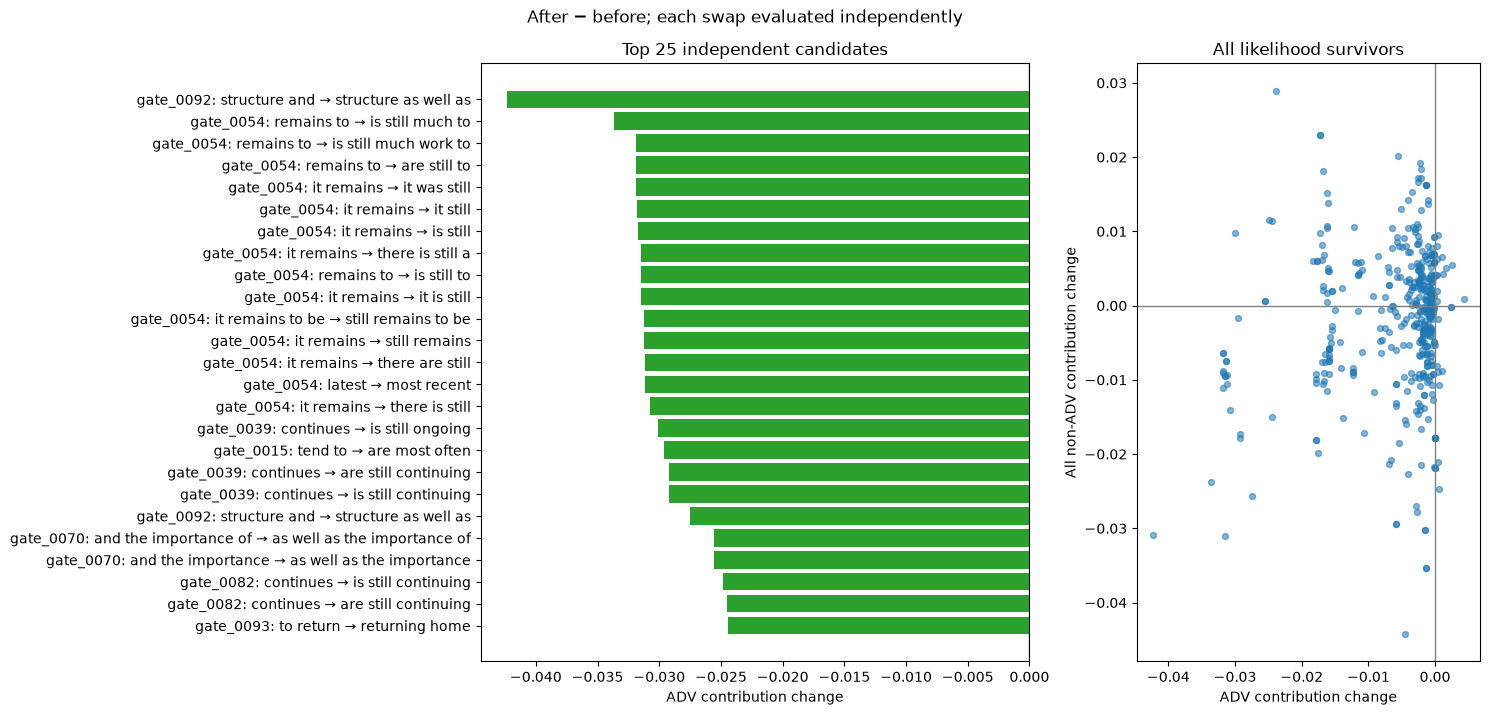

Saved: ../results/causal/C03c_targeted_X_edits/498ff07c2a43/step55_383dbcadf28b/PPDB_ADV/f5af7a8aaadb/likelihood_gate/contribution_evaluation/d0277da054e5
No swaps applied. Candidate rows are alternatives, not independent experimental documents.


In [21]:
# Run after C03g likelihood gate. Independent swaps against unchanged step-5.5 texts.
from pathlib import Path
import hashlib, json, pickle, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

required = ['ll_result','pp_texts','pp_frame','full_frame','contributions','COLS','detector','ll_dir','ROOT']
assert all(k in globals() for k in required), 'Run the step-5.5 and likelihood cells first.'
assert len(COLS) == 186 and list(detector.feature_names_in_) == list(COLS)
# Freeze the pilot threshold, independently of later interactive threshold changes.
cc_pool = ll_result.loc[ll_result.ll_status.eq('scored') & ll_result.delta_logp.ge(-1.0)].copy()
assert cc_pool.candidate_id.is_unique
assert len(pp_texts) == len(pp_frame)
cc_contract = dict(version='independent_ADV_contributions_v1', threshold=-1.0,
    columns=list(COLS), baseline_texts=list(pp_texts),
    baseline_cases=pp_frame.case_id.astype(str).tolist(),
    detector_sha256=hashlib.sha256(pickle.dumps(detector)).hexdigest(),
    extractor_sha256=hashlib.sha256(__import__('marshal').dumps(full_frame.__code__)).hexdigest())
cc_run = hashlib.sha256(json.dumps(cc_contract,sort_keys=True).encode()).hexdigest()[:12]
cc_out = Path(ll_dir)/'contribution_evaluation'/cc_run
cc_out.mkdir(parents=True,exist_ok=True)
(cc_out/'contract.json').write_text(json.dumps(cc_contract,indent=2))
cc_cache = cc_out/'vectors'; cc_cache.mkdir(exist_ok=True)
CC_BATCH_SIZE = 8

def cc_key(text):
    return hashlib.sha256(text.encode()).hexdigest()

def cc_load(text):
    path = cc_cache/(cc_key(text)+'.npz')
    if not path.exists(): return None
    with np.load(path,allow_pickle=False) as f:
        x,c = f['features'],f['contributions']
        assert x.shape == c.shape == (186,)
        assert np.isfinite(x).all() and np.isfinite(c).all()
        return x,c

def cc_score(texts,label):
    unique = list(dict.fromkeys(texts))
    missing = [t for t in unique if cc_load(t) is None]
    print(f'{label}: {len(unique)-len(missing)} cached; {len(missing)} to score.',flush=True)
    started = time.monotonic()
    for offset in range(0,len(missing),CC_BATCH_SIZE):
        batch = missing[offset:offset+CC_BATCH_SIZE]
        x = full_frame(batch)
        assert list(x.columns) == list(COLS)
        c = np.asarray(contributions(x))
        assert c.shape == x.shape and np.isfinite(c).all()
        for text,fx,fc in zip(batch,x.to_numpy(),c):
            dest = cc_cache/(cc_key(text)+'.npz')
            temp = dest.with_suffix('.tmp')
            with temp.open('wb') as f:
                np.savez_compressed(f,features=fx,contributions=fc)
            temp.replace(dest)
        count = offset+len(batch)
        elapsed = time.monotonic()-started
        print(f'{label}: {count}/{len(missing)} | {elapsed:.0f}s elapsed | '
              f'~{elapsed/count*(len(missing)-count)/60:.1f} min remaining',flush=True)

cc_edited = []
for r in cc_pool.itertuples():
    i,a,b = int(r.row_index),int(r.start),int(r.end)
    assert str(pp_frame.iloc[i].case_id) == str(r.case_id)
    assert pp_texts[i][a:b] == r.source
    cc_edited.append(pp_texts[i][:a]+r.replacement+pp_texts[i][b:])

cc_parents = cc_pool.row_index.to_numpy(dtype=int)
cc_score([pp_texts[i] for i in cc_parents],'Baseline')
cc_score(cc_edited,'Candidates')
if not cc_edited:
    print('No likelihood survivors to score.')
else:
    bx,bc = zip(*(cc_load(pp_texts[i]) for i in cc_parents))
    ax,ac = zip(*(cc_load(t) for t in cc_edited))
    dx,dc = np.asarray(ax)-np.asarray(bx),np.asarray(ac)-np.asarray(bc)
    cc_results = cc_pool.copy().reset_index(drop=True)
    blocks = {}
    for tag in ['ADV','ADP','NUM','X']:
        blocks[tag] = [i for i,c in enumerate(COLS) if c.startswith(f'pos_{tag}_')]
        assert len(blocks[tag]) == 4
        cc_results[f'{tag}_contribution_change'] = dc[:,blocks[tag]].sum(axis=1)
    target_ix = sorted(set(sum(blocks.values(),[])))
    other_ix = [i for i in range(len(COLS)) if i not in target_ix]
    cc_results['other_features_change'] = dc[:,other_ix].sum(axis=1)
    cc_results['non_ADV_change'] = dc.sum(axis=1)-dc[:,blocks['ADV']].sum(axis=1)
    cc_results['total_contribution_change'] = dc.sum(axis=1)
    cc_results['ADV_improved'] = cc_results.ADV_contribution_change.lt(-1e-12)
    cc_results['non_ADV_worsened'] = cc_results.non_ADV_change.gt(1e-12)
    cc_results['largest_positive_feature'] = [COLS[i] for i in dc.argmax(axis=1)]
    cc_results['largest_positive_change'] = dc.max(axis=1)
    cc_results.to_csv(cc_out/'candidate_results.csv',index=False)
    pd.DataFrame(dc,index=cc_results.candidate_id,columns=COLS).to_csv(cc_out/'feature_contribution_changes.csv')
    pd.DataFrame(dx,index=cc_results.candidate_id,columns=COLS).to_csv(cc_out/'raw_feature_changes.csv')
    display(cc_results.groupby(['ADV_improved','non_ADV_worsened']).agg(
        candidates=('candidate_id','size'), cases=('case_id','nunique')))
    view = ['case_id','source','replacement','delta_logp','ADV_contribution_change',
            'ADP_contribution_change','NUM_contribution_change','X_contribution_change',
            'other_features_change','total_contribution_change']
    display(cc_results.sort_values('ADV_contribution_change')[view].head(30))
    # Descriptive best independent candidate per case, not cumulative results.
    best = cc_results.sort_values(['ADV_contribution_change','candidate_id']).drop_duplicates('case_id')
    best.to_csv(cc_out/'best_independent_candidate_per_case.csv',index=False)
    print(f'Cases with at least one ADV-improving candidate: '
          f'{cc_results.loc[cc_results.ADV_improved,"case_id"].nunique()}/{len(pp_frame)}')
    shown = cc_results.sort_values('ADV_contribution_change').head(25).iloc[::-1]
    fig,axes = plt.subplots(1,2,figsize=(15,max(5,len(shown)*.29)),gridspec_kw={'width_ratios':[1.6,1]})
    axes[0].barh(range(len(shown)),shown.ADV_contribution_change,
        color=['tab:green' if v < 0 else 'tab:orange' for v in shown.ADV_contribution_change])
    axes[0].set_yticks(range(len(shown)),[f'{r.case_id}: {r.source} → {r.replacement}' for r in shown.itertuples()])
    axes[0].set_xlabel('ADV contribution change'); axes[0].axvline(0,color='gray',lw=1)
    axes[0].set_title('Top 25 independent candidates')
    axes[1].scatter(cc_results.ADV_contribution_change,cc_results.non_ADV_change,alpha=.55,s=18)
    axes[1].axhline(0,color='gray',lw=1);axes[1].axvline(0,color='gray',lw=1)
    axes[1].set_xlabel('ADV contribution change');axes[1].set_ylabel('All non-ADV contribution change')
    axes[1].set_title('All likelihood survivors')
    fig.suptitle('After − before; each swap evaluated independently')
    fig.tight_layout()
    for folder in [cc_out,Path(ROOT)/'figures']:
        folder.mkdir(parents=True,exist_ok=True)
        for ext in ['pdf','png']:
            fig.savefig(folder/f'C03h_ADV_candidate_contributions_{cc_run}.{ext}',bbox_inches='tight',dpi=180)
    plt.show()
    print('Saved:',cc_out)
    print('No swaps applied. Candidate rows are alternatives, not independent experimental documents.')


Frozen scorer: gpt2 607a30d783dfa663caf39e06633721c8d4cfcd7e


Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████| 148/148 [00:00<00:00, 11247.02it/s]


429 candidates; 663 uncached scoring windows on cuda.
Scored 8/663 windows (0s)
Scored 16/663 windows (0s)
Scored 24/663 windows (0s)
Scored 32/663 windows (0s)
Scored 40/663 windows (0s)
Scored 48/663 windows (0s)
Scored 56/663 windows (0s)
Scored 64/663 windows (0s)
Scored 72/663 windows (0s)
Scored 80/663 windows (1s)
Scored 88/663 windows (1s)
Scored 96/663 windows (1s)
Scored 104/663 windows (1s)
Scored 112/663 windows (1s)
Scored 120/663 windows (1s)
Scored 128/663 windows (1s)
Scored 136/663 windows (1s)
Scored 144/663 windows (1s)
Scored 152/663 windows (1s)
Scored 160/663 windows (1s)
Scored 168/663 windows (1s)
Scored 176/663 windows (1s)
Scored 184/663 windows (1s)
Scored 192/663 windows (1s)
Scored 200/663 windows (1s)
Scored 208/663 windows (1s)
Scored 216/663 windows (1s)
Scored 224/663 windows (1s)
Scored 232/663 windows (2s)
Scored 240/663 windows (2s)
Scored 248/663 windows (2s)
Scored 256/663 windows (2s)
Scored 264/663 windows (2s)
Scored 272/663 windows (2s)
Scored 

,candidates,cases
likelihood_pass,,
False,225,41
True,204,43


,case_id,source,replacement,delta_logp,likelihood_pass,before_sentence,after_sentence
344,gate_0024,sources,sourcing,-3.533226,False,"The ministry has its sights set on the United States, with sources close to the matter indicating that the U.S. is the top candidate.","The ministry has its sights set on the United States, with sourcing close to the matter indicating that the U.S. is the top candidate."
412,gate_0024,understanding of,understood it,-3.267531,False,The finance ministry is now in the process of recruiting a new governor with extensive experience in leading large financial institutions and a deep underst...,The finance ministry is now in the process of recruiting a new governor with extensive experience in leading large financial institutions and a deep underst...
79,gate_0094,continue to,is continually,-2.941082,False,While others believe they will continue to exist in a more limited capacity.,While others believe they will is continually exist in a more limited capacity.
114,gate_0027,development of,further develop,-2.877317,False,"Historically, it played a crucial role in the economic development of Fife, providing employment for many years.","Historically, it played a crucial role in the economic further develop Fife, providing employment for many years."
339,gate_0003,required to,needed so,-2.754911,False,"Under the proposed scheme, individuals who voluntarily disclose their hidden assets will be exempt from prosecution, and will only be required to pay a fine.","Under the proposed scheme, individuals who voluntarily disclose their hidden assets will be exempt from prosecution, and will only be needed so pay a fine."
406,gate_0024,understanding of,better understand,-2.625465,False,The finance ministry is now in the process of recruiting a new governor with extensive experience in leading large financial institutions and a deep underst...,The finance ministry is now in the process of recruiting a new governor with extensive experience in leading large financial institutions and a deep better ...
391,gate_0066,to raise,further increase,-2.603666,False,"Parmalat, Italy's largest food company, was forced into administration in December, when it failed to raise the promised funds for a bond repayment of $500 ...","Parmalat, Italy's largest food company, was forced into administration in December, when it failed further increase the promised funds for a bond repayment ..."
396,gate_0005,to sign,signatories to,-2.601119,False,"When I tried to sign in, it said ""It's not done yet,"" but the page just showed a blank screen the first time I tried.","When I tried signatories to in, it said ""It's not done yet,"" but the page just showed a blank screen the first time I tried."
383,gate_0093,to increase,further increased,-2.599144,False,"Nigeria plans to significantly boost its cocoa production over the next decade, aiming to increase its cocoa bean output by 50% by 2030, according to Presid...","Nigeria plans to significantly boost its cocoa production over the next decade, aiming further increased its cocoa bean output by 50% by 2030, according to ..."
176,gate_0065,is about,is shortly,-2.590752,False,"It starts with the introduction of a new town; It is a little quaint, and people look healthy; The book is about its residents and their lives compared to h...","It starts with the introduction of a new town; It is a little quaint, and people look healthy; The book is shortly its residents and their lives compared to..."


Local likelihood scoring complete; selecting one swap per document next.
Selected 30 swaps across 54 documents.


,block,mean_change,ci_low,ci_high
0,ADV,-0.005449,-0.008246,-0.003053
1,ADP,-0.000075,-0.000441,0.000330
2,NUM,-0.000193,-0.000457,0.000055
3,X,-0.000121,-0.000231,-0.000027
4,Other,-0.003657,-0.005590,-0.002042
5,Total,-0.009495,-0.013889,-0.005641


,case_id,source,replacement,delta_logp,local_delta_logp,ADV_contribution_change,non_ADV_change
347,gate_0092,structure and,structure as well as,-0.013654,0.204415,-0.042347,-0.030859
328,gate_0054,remains to,is still much to,-0.454504,-0.548633,-0.033628,-0.023801
350,gate_0015,tend to,are most often,-0.142852,-0.839269,-0.029607,-0.001690
88,gate_0039,continues,is still continuing,-0.328664,-0.383881,-0.029218,-0.017894
1,gate_0026,a limited,only limited,-0.131381,-0.761600,-0.017902,-0.009269
62,gate_0081,before making,prior to making,-0.080021,-0.373177,-0.017846,-0.010404
186,gate_0019,is just,is only just,-0.227827,-0.457437,-0.016663,-0.010115
367,gate_0016,Throughout the,All over the,-0.138010,-0.740309,-0.015961,-0.006608
319,gate_0079,remains a,is still,-0.078878,-0.541972,-0.013792,-0.015114
416,gate_0003,will encourage,will further encourage,-0.061309,-0.256512,-0.011581,-0.000755


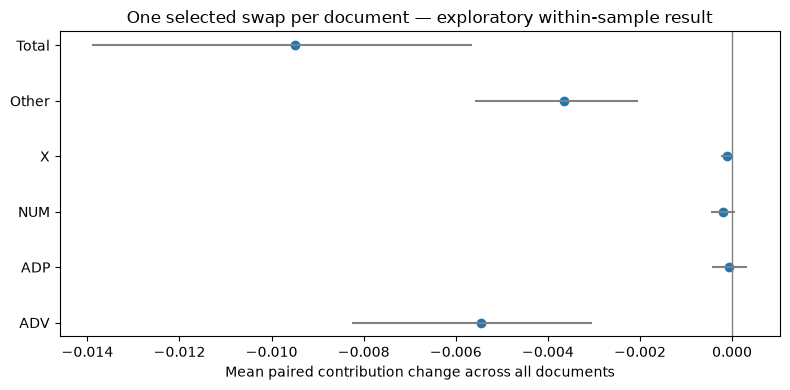

Intervals resample documents after selection; they do not measure held-out generalization.
New texts saved separately; step-5.5 baseline is unchanged.


In [22]:
# Run after PPDB retagging. No PPDB rescan or POS parsing.
from pathlib import Path
import hashlib, json, re, time
import numpy as np
import pandas as pd
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from IPython.display import display

LG_THRESHOLD = -1.0  # nats/token; permissive initial setting, not calibrated
CONTEXT_WORDS = 48
LG_BATCH_SIZE = 8

# Read the frozen scorer from the same contract used by C02w0.
lg_treatment_path = Path(ROOT) / 'results/causal/C02r_discovery_gated_punctuation/treatment_contract.json'
lg_treatment = json.loads(lg_treatment_path.read_text())
LG_MODEL_ID = lg_treatment['scorer']
LG_REVISION = lg_treatment['scorer_revision']
print('Frozen scorer:', LG_MODEL_ID, LG_REVISION, flush=True)
assert re.fullmatch(r'[0-9a-fA-F]{40}', str(LG_REVISION)), 'Use the frozen scorer commit SHA, not a moving branch.'

assert 'cc_results' in globals(), 'Run C03h first.'
lg_pool = pp_review.loc[pp_review.candidate_id.isin(cc_results.candidate_id)].copy()
assert lg_pool.candidate_id.is_unique
lg_tokenizer = AutoTokenizer.from_pretrained(LG_MODEL_ID, revision=LG_REVISION, use_fast=True)
assert lg_tokenizer.is_fast
lg_tokenizer.pad_token = lg_tokenizer.eos_token
lg_model = AutoModelForCausalLM.from_pretrained(LG_MODEL_ID, revision=LG_REVISION)
lg_device = 'cuda' if torch.cuda.is_available() else 'cpu'
lg_model.to(lg_device).eval()
lg_max_length = getattr(lg_model.config, 'max_position_embeddings', getattr(lg_model.config, 'n_positions', 1024))
lg_contract = dict(version='local_likelihood_eight_following_tokens_v1', scorer=LG_MODEL_ID,
                   revision=LG_REVISION, context_words=CONTEXT_WORDS,
                   score='mean_logp_edit_plus_first_8_following_tokens', torch=torch.__version__,
                   device=lg_device, batch_size=LG_BATCH_SIZE)
lg_dir = Path(pp_out)/'local_likelihood_gate'
lg_dir.mkdir(parents=True, exist_ok=True)
lg_cache_path = lg_dir/'scores.json'
lg_cache = json.loads(lg_cache_path.read_text()) if lg_cache_path.exists() else {}

def lg_save_cache():
    temp = lg_cache_path.with_suffix('.tmp')
    temp.write_text(json.dumps(lg_cache))
    temp.replace(lg_cache_path)

def lg_encode(left, span, right):
    text = left + span + right
    encoded = lg_tokenizer(text, add_special_tokens=False, return_offsets_mapping=True)
    ids = encoded['input_ids']
    # Include a boundary-straddling token rather than silently omitting edit text.
    boundary = len(left) + len(span)
    offsets = encoded['offset_mapping']
    following = [i for i,(start,end) in enumerate(offsets) if start >= boundary][:8]
    mask = [(end > len(left) and start < boundary) or i in following
            for i,(start,end) in enumerate(offsets)]
    # A token straddling the edit boundary is counted as part of the edit.
    last = max(i for i,keep in enumerate(mask) if keep) + 1
    ids, mask = ids[:last], mask[:last]
    if not left:
        ids = [lg_tokenizer.bos_token_id or lg_tokenizer.eos_token_id] + ids
        mask = [False] + mask
    return ids, mask

lg_jobs, lg_rows = {}, []
for row in lg_pool.itertuples():
    i, start, end = int(row.row_index), int(row.start), int(row.end)
    text = pp_texts[i]
    assert text[start:end] == row.source, 'Candidate/text alignment changed.'
    prefix, suffix = text[:start], text[end:]
    left_words, right_words = list(re.finditer(r'\S+', prefix)), list(re.finditer(r'\S+', suffix))
    left = prefix[left_words[-CONTEXT_WORDS].start():] if len(left_words) > CONTEXT_WORDS else prefix
    right = suffix[:right_words[CONTEXT_WORDS-1].end()] if len(right_words) > CONTEXT_WORDS else suffix
    original = lg_encode(left, row.source, right)
    edited = lg_encode(left, row.replacement, right)
    if max(len(original[0]), len(edited[0])) > lg_max_length:
        lg_rows.append(dict(candidate_id=row.candidate_id, lg_status='context_too_long',
                            original_key=None, edited_key=None))
        continue  # Explicitly report; never silently truncate away the right context.
    keys = []
    for encoded in [original, edited]:
        key = hashlib.sha256(json.dumps([lg_contract, encoded], sort_keys=True).encode()).hexdigest()
        keys.append(key)
        if key not in lg_cache:
            lg_jobs[key] = encoded
    lg_rows.append(dict(candidate_id=row.candidate_id, lg_status='scored',
                        original_key=keys[0], edited_key=keys[1]))

pending = list(lg_jobs.items())
print(f'{len(lg_pool)} candidates; {len(pending)} uncached scoring windows on {lg_device}.', flush=True)
started = time.monotonic()
for offset in range(0, len(pending), LG_BATCH_SIZE):
    batch = pending[offset:offset+LG_BATCH_SIZE]
    width = max(len(value[0]) for _, value in batch)
    ids = torch.full((len(batch), width), lg_tokenizer.pad_token_id, dtype=torch.long, device=lg_device)
    attention = torch.zeros_like(ids)
    scored = torch.zeros_like(ids, dtype=torch.bool)
    for j, (_, (tokens, mask)) in enumerate(batch):
        ids[j,:len(tokens)] = torch.tensor(tokens, device=lg_device)
        attention[j,:len(tokens)] = 1
        scored[j,:len(tokens)] = torch.tensor(mask, device=lg_device)
    with torch.inference_mode():
        logits = lg_model(input_ids=ids, attention_mask=attention, use_cache=False).logits
        losses = torch.nn.functional.cross_entropy(
            logits[:,:-1].reshape(-1, logits.shape[-1]), ids[:,1:].reshape(-1), reduction='none'
        ).reshape(len(batch), -1)
        valid = scored[:,1:] & attention[:,1:].bool()
        counts = valid.sum(dim=1)
        assert (counts > 0).all()
        means = -(losses*valid).sum(dim=1)/counts
    for j, (key, _) in enumerate(batch):
        lg_cache[key] = dict(mean_logp=float(means[j].cpu()), scored_tokens=int(counts[j].cpu()))
    del logits, losses, means, ids, attention, scored, valid, counts
    lg_save_cache()
    print(f'Scored {min(offset+LG_BATCH_SIZE,len(pending))}/{len(pending)} windows '
          f'({time.monotonic()-started:.0f}s)', flush=True)

lg_result = lg_pool.merge(pd.DataFrame(lg_rows), on='candidate_id', validate='one_to_one')
for label in ['original', 'edited']:
    lg_result[f'{label}_mean_logp'] = lg_result[f'{label}_key'].map(
        lambda key: lg_cache[key]['mean_logp'] if key in lg_cache else np.nan)
lg_result['delta_logp'] = lg_result.edited_mean_logp-lg_result.original_mean_logp
lg_result['likelihood_pass'] = lg_result.lg_status.eq('scored') & lg_result.delta_logp.ge(LG_THRESHOLD)
lg_result.to_csv(lg_dir/'candidate_likelihoods.csv', index=False)
(lg_dir/'contract.json').write_text(json.dumps({**lg_contract, 'threshold':LG_THRESHOLD}, indent=2))
lg_passed = lg_result.loc[lg_result.likelihood_pass].copy()
lg_passed.to_csv(lg_dir/'likelihood_passed.csv', index=False)
display(lg_result.groupby('likelihood_pass').agg(candidates=('candidate_id','size'), cases=('case_id','nunique')))
with pd.option_context('display.max_colwidth', 160):
    display(lg_result.sort_values('delta_logp')[['case_id','source','replacement','delta_logp',
               'likelihood_pass','before_sentence','after_sentence']].head(30))
print('Local likelihood scoring complete; selecting one swap per document next.')
# Release only this cell's scorer; preserve the frozen FZ186 detector.
del lg_model
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Deterministic one-swap-per-document pilot using cached C03h contributions.
# Both likelihood thresholds are fixed at -1.0 for this exploratory run.
lg_joint = cc_results.merge(
    lg_result[['candidate_id','delta_logp','likelihood_pass']].rename(
        columns={'delta_logp':'local_delta_logp','likelihood_pass':'local_pass'}),
    on='candidate_id',validate='one_to_one')
lg_joint['eligible'] = (
    lg_joint.delta_logp.ge(-1.0) & lg_joint.local_pass
    & lg_joint.ADV_contribution_change.lt(-1e-12)
    & lg_joint.non_ADV_change.le(1e-12)
)
# Largest ADV drop; ties prefer higher local likelihood, then stable candidate ID.
lg_selected = (lg_joint.loc[lg_joint.eligible]
    .sort_values(['ADV_contribution_change','local_delta_logp','candidate_id'],
                 ascending=[True,False,True])
    .drop_duplicates('case_id'))
lg_joint.to_csv(lg_dir/'all_gates_and_contributions.csv',index=False)
lg_selected.to_csv(lg_dir/'selected_swaps.csv',index=False)
lg_final = pp_frame.copy().reset_index(drop=True)
lg_final['text'] = list(pp_texts)
lg_final['candidate_id'] = ''
lg_changes = np.zeros((len(pp_frame),len(COLS)))
for r in lg_selected.itertuples():
    i,a,b = int(r.row_index),int(r.start),int(r.end)
    assert str(pp_frame.iloc[i].case_id) == str(r.case_id)
    assert pp_texts[i][a:b] == r.source
    edited = pp_texts[i][:a]+r.replacement+pp_texts[i][b:]
    baseline, treatment = cc_load(pp_texts[i]),cc_load(edited)
    assert baseline is not None and treatment is not None, 'C03h cache missing.'
    lg_changes[i] = treatment[1]-baseline[1]
    lg_final.at[i,'text'] = edited
    lg_final.at[i,'candidate_id'] = r.candidate_id
lg_final.to_csv(lg_dir/'one_swap_per_document_texts.csv',index=False)
pd.DataFrame(lg_changes,index=pp_frame.case_id,columns=COLS).to_csv(lg_dir/'paired_feature_changes.csv')

# All original documents included; unchanged documents contribute exactly zero.
lg_blocks = {}
for tag in ['ADV','ADP','NUM','X']:
    lg_blocks[tag] = [i for i,c in enumerate(COLS) if c.startswith(f'pos_{tag}_')]
lg_used = set(sum(lg_blocks.values(),[]))
lg_blocks['Other'] = [i for i in range(len(COLS)) if i not in lg_used]
lg_blocks['Total'] = list(range(len(COLS)))
rng = np.random.default_rng(20260909)
resamples = rng.integers(0,len(pp_frame),size=(3000,len(pp_frame)))
lg_summary_rows = []
for name,ix in lg_blocks.items():
    v = lg_changes[:,ix].sum(axis=1)
    lo,hi = np.quantile(v[resamples].mean(axis=1),[.025,.975])
    lg_summary_rows.append(dict(block=name,mean_change=v.mean(),ci_low=lo,ci_high=hi))
lg_summary = pd.DataFrame(lg_summary_rows)
lg_summary.to_csv(lg_dir/'paired_block_summary.csv',index=False)
print(f'Selected {len(lg_selected)} swaps across {len(pp_frame)} documents.')
display(lg_summary)
display(lg_selected[['case_id','source','replacement','delta_logp','local_delta_logp',
                     'ADV_contribution_change','non_ADV_change']])
import matplotlib.pyplot as plt
fig,ax = plt.subplots(figsize=(8,4))
y = np.arange(len(lg_summary))
ax.hlines(y,lg_summary.ci_low,lg_summary.ci_high,color='gray')
ax.scatter(lg_summary.mean_change,y)
ax.set_yticks(y,lg_summary.block);ax.axvline(0,color='gray',lw=1)
ax.set_xlabel('Mean paired contribution change across all documents')
ax.set_title('One selected swap per document — exploratory within-sample result')
fig.tight_layout()
for directory in [lg_dir,Path(ROOT)/'figures']:
    directory.mkdir(parents=True,exist_ok=True)
    for ext in ['pdf','png']:
        fig.savefig(directory/f'C03i_local_gate_one_swap_{cc_run}.{ext}',bbox_inches='tight',dpi=180)
plt.show()
print('Intervals resample documents after selection; they do not measure held-out generalization.')
print('New texts saved separately; step-5.5 baseline is unchanged.')

In [2]:
# Run after C03i. Evaluate the accepted 30-swap output with frozen FZ186.
from pathlib import Path
import json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
from IPython.display import display

assert len(COLS)==186 and list(detector.feature_names_in_)==list(COLS)
assert lg_final.case_id.tolist()==pp_frame.case_id.tolist()
ev_texts=lg_final.text.astype(str).tolist()
ev_id=hashlib.sha256(json.dumps(ev_texts).encode()).hexdigest()[:12]
ev_out=Path(lg_dir)/'accepted_evaluation'/ev_id
ev_out.mkdir(parents=True,exist_ok=True)

def ev_save(fig,stem):
    fig.tight_layout()
    for directory in [ev_out,Path(ROOT)/'figures']:
        directory.mkdir(parents=True,exist_ok=True)
        for ext in ['pdf','png']:
            fig.savefig(directory/f'C03j_{stem}_{ev_id}.{ext}',bbox_inches='tight',dpi=180)
    plt.show()

# Reuse completed candidate caches; compute only previously uncached baselines.
cc_score(list(pp_texts)+ev_texts,'AI evaluation')
ev_before_x=np.array([cc_load(t)[0] for t in pp_texts])
ev_after_x=np.array([cc_load(t)[0] for t in ev_texts])
ev_before_c=np.array([cc_load(t)[1] for t in pp_texts])
ev_after_c=np.array([cc_load(t)[1] for t in ev_texts])
ev_before=detector.predict_proba(pd.DataFrame(ev_before_x,columns=COLS))[:,1]
ev_after=detector.predict_proba(pd.DataFrame(ev_after_x,columns=COLS))[:,1]
np.testing.assert_allclose(ev_after-ev_before,(ev_after_c-ev_before_c).sum(1),atol=1e-8)

# Read the exact original manifests; preserve calibration/test separation and weights.
ev_man={s:pd.read_csv(Path(RUN_DIR)/f'human_{s}_manifest.csv') for s in ['calibration','test']}
ev_hscores={}
ev_hcache=Path(lg_dir)/'frozen_human_scores'
ev_hcache.mkdir(exist_ok=True)
for split,m in ev_man.items():
    assert m.source_id.is_unique and np.isclose(m.weight.sum(),1)
    key=hashlib.sha256((cc_run+m.to_csv(index=False)).encode()).hexdigest()[:16]
    cached=ev_hcache/f'{split}_{key}.csv'
    if cached.exists():
        saved=pd.read_csv(cached)
        assert saved.source_id.tolist()==m.source_id.tolist()
        ev_hscores[split]=saved.score.to_numpy()
        print(f'{split}: reused frozen human scores.',flush=True)
        continue
    # Original C03 feature frame, if still present in this kernel.
    available=False
    if 'XR' in globals() and 'raid' in globals() and len(XR)==len(raid):
        if set(COLS)<=set(XR.columns) and raid.source_id.is_unique:
            lookup=pd.Series(np.arange(len(raid)),index=raid.source_id)
            if m.source_id.isin(lookup.index).all():
                hx=XR.iloc[lookup.loc[m.source_id].to_numpy()][COLS]
                available=True
    if not available:
        print(f'{split}: loading {len(m)} frozen human feature vectors.',flush=True)
        corp=pd.read_parquet(Path(BASE)/'paired_corpus.parquet',columns=['source_id','text'])
        assert corp.source_id.is_unique
        texts=corp.set_index('source_id').loc[m.source_id,'text'].map(normalize).tolist()
        parts=[]
        for offset in range(0,len(texts),16):
            chunk=texts[offset:offset+16]
            ck=hashlib.sha256(json.dumps([cc_run,chunk]).encode()).hexdigest()
            fp=ev_hcache/f'features_{ck}.npz'
            if fp.exists():
                with np.load(fp,allow_pickle=False) as f: values=f['values']
            else:
                values=full_frame(chunk).to_numpy()
                tmp=fp.with_suffix('.tmp')
                with tmp.open('wb') as f:np.savez_compressed(f,values=values)
                tmp.replace(fp)
            assert values.shape==(len(chunk),186)
            parts.append(values)
            print(f'{split}: {offset+len(chunk)}/{len(texts)} features ready',flush=True)
        hx=pd.DataFrame(np.concatenate(parts),columns=COLS)
    ev_hscores[split]=detector.predict_proba(hx)[:,1]
    m.assign(score=ev_hscores[split]).to_csv(cached,index=False)

cal,h=ev_hscores['calibration'],ev_hscores['test']
wc,wh=ev_man['calibration'].weight.to_numpy(),ev_man['test'].weight.to_numpy()
cuts=np.r_[np.inf,np.unique(cal)[::-1],-np.inf]
cf=np.array([wc[cal>v].sum() for v in cuts])
ev_ops=[]
for budget in [.01,.05,.10,.20,.30,.50,1.]:
    j=np.flatnonzero(cf<=budget+1e-12)[-1];cut=cuts[j]
    ev_ops.append(dict(requested_FPR=budget,calibration_FPR=cf[j],test_FPR=wh[h>cut].sum(),
        threshold=cut,After_step55_TPR=(ev_before>cut).mean(),After_ADV_TPR=(ev_after>cut).mean(),
        Before_detected=int((ev_before>cut).sum()),After_detected=int((ev_after>cut).sum()),n_AI=len(ev_after)))
ev_tpr=pd.DataFrame(ev_ops);ev_tpr.to_csv(ev_out/'TPR_staircase.csv',index=False);display(ev_tpr)
fig,axes=plt.subplots(1,2,figsize=(11,4));summaries=[];rocrows=[]
for name,scores in [('After step 5.5',ev_before),('After ADV',ev_after)]:
    f,t,_=roc_curve(np.r_[np.zeros(len(h)),np.ones(len(scores))],np.r_[h,scores],
                   sample_weight=np.r_[wh,np.ones(len(scores))/len(scores)],drop_intermediate=False)
    area=auc(f,t);summaries.append(dict(stage=name,AUC=area,mean_AI_score=scores.mean()))
    rocrows.extend(dict(stage=name,FPR=x,TPR=y) for x,y in zip(f,t))
    for ax in axes:ax.step(f,t,where='post',label=f'{name} ({area:.3f})')
for ax in axes:
    ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Genre-weighted test human FPR',ylabel='AI TPR');ax.legend()
axes[1].set_xlim(0,.2);ev_save(fig,'ADV_ROC')
pd.DataFrame(rocrows).to_csv(ev_out/'ROC_points.csv',index=False)
ev_summary=pd.DataFrame(summaries);ev_summary.to_csv(ev_out/'summary.csv',index=False);display(ev_summary)
lg_final.assign(before_AI_score=ev_before,after_AI_score=ev_after).to_csv(ev_out/'accepted_texts_and_scores.csv',index=False)

# Recover the fixed same-genre reference in original case order, without refitting it.
stored_c=pd.read_csv(Path(RUN_DIR)/'FZ186_case_contributions.csv').set_index('case_id').loc[pp_frame.case_id,COLS].to_numpy()
stored_g=pd.read_csv(Path(RUN_DIR)/'FZ186_case_contribution_gaps.csv').set_index('case_id').loc[pp_frame.case_id,COLS].to_numpy()
ev_ref=stored_c-stored_g
bg,ag=ev_before_c-ev_ref,ev_after_c-ev_ref
rng=np.random.default_rng(20260909);B=3000
boot=np.zeros((B,186));boot_change=np.zeros_like(boot)
for genre in sorted(pp_frame.domain.unique()):
    ix=np.flatnonzero(pp_frame.domain.eq(genre));draw=rng.choice(ix,size=(B,len(ix)),replace=True)
    boot+=len(ix)/len(pp_frame)*ag[draw].mean(axis=1)
    boot_change+=len(ix)/len(pp_frame)*(ag-bg)[draw].mean(axis=1)
lo,hi=np.quantile(boot,[.025,.975],axis=0);cl,ch=np.quantile(boot_change,[.025,.975],axis=0)
ev_rank=pd.DataFrame(dict(feature=COLS,raw_mean_contribution=ev_after_c.mean(0),before_gap=bg.mean(0),
    human_adjusted_gap=ag.mean(0),ci_low=lo,ci_high=hi,contribution_change=(ag-bg).mean(0),
    change_ci_low=cl,change_ci_high=ch,fraction_AI_directed=(ag>0).mean(0))).sort_values('human_adjusted_gap',ascending=False)
ev_rank.to_csv(ev_out/'remaining_contributions.csv',index=False)
pd.DataFrame(ag,index=pp_frame.case_id,columns=COLS).to_csv(ev_out/'case_contribution_gaps.csv')
display(ev_rank.head(30))
top=ev_rank.head(30).iloc[::-1];y=np.arange(len(top));fig,ax=plt.subplots(figsize=(10,10))
ax.hlines(y,top.ci_low,top.ci_high,color='gray',alpha=.65)
ax.scatter(top.before_gap,y,label='After step 5.5');ax.scatter(top.human_adjusted_gap,y,label='After ADV')
ax.set_yticks(y,top.feature);ax.axvline(0,color='gray');ax.legend()
ax.set_title('Frozen FZ186 — top 30 remaining AI-directed contributions')
ax.set_xlabel('Mean contribution minus fixed same-genre human reference');ev_save(fig,'remaining_contributions')
(ev_out/'contract.json').write_text(json.dumps(dict(detector_run=str(RUN_DIR),selection_run=str(lg_dir),
    contribution_cache_run=cc_run,accepted_text_hash=ev_id,comparison='step55_vs_accepted_ADV',
    threshold_rule='original calibration, strict score > threshold',bootstrap='genre-stratified documents; post-selection descriptive'),indent=2))
print('Saved evaluation:',ev_out)
print('Accepted output: accepted_texts_and_scores.csv. Next POS work should start from these texts.')

NameError: name 'COLS' is not defined

In [26]:
from pathlib import Path
import shutil

source_dir = Path("../figures")
figure_dir = Path(ROOT) / 'figures'
figure_dir.mkdir(parents=True, exist_ok=True)
for old_stem, new_stem in [
    ('C03j_ADV_ROC', 'C03c_steps56_ROC'),
    ('C03j_remaining_contributions', 'C03c_steps56_remaining_contributions'),
]:
    for extension in ['pdf', 'png']:
        candidates = sorted(source_dir.glob(f'{old_stem}_*.{extension}'))
        assert len(candidates) == 1, f'Expected one {old_stem} {extension} in {source_dir}: {candidates}'
        destination = figure_dir / f'{new_stem}.{extension}'
        shutil.copy2(candidates[0], destination)
        print(destination)

../figures/C03c_steps56_ROC.pdf
../figures/C03c_steps56_ROC.png
../figures/C03c_steps56_remaining_contributions.pdf
../figures/C03c_steps56_remaining_contributions.png
